In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from statsmodels.graphics.gofplots import qqplot

# Load data gempa bumi
data = pd.read_excel('/content/Data Gempa Bumi.xlsx')
data = data.values
data = data.flatten()

===== Uji Normalitas Data Asli =====
Shapiro-Wilk Test: p-value = 0.00013480761555148755
Kolmogorov-Smirnov Test: p-value = 0.07959144099773649

===== Resampling dengan ukuran 50 =====
Bootstrap - Estimator Mean: 3.6194960000000003, Variance Mean: 0.004107341325325327, Bias Mean: 0.0014563809523804316, MSE Mean: 0.004105355029478459
Monte Carlo - Estimator Mean: 3.6214819969665086, Variance Mean: 0.0048915027737947364, Bias Mean: 0.0005296160141279316, MSE Mean: 0.004886891764143363
Bootstrap - Estimator Skew: 0.560630482590623, Variance Skew: 0.053128099836759084, Bias Skew: 0.013331721965531229, MSE Skew: 0.05325270654748855
Monte Carlo - Estimator Skew: 0.45455276472415335, Variance Skew: 0.06245015411831804, Bias Skew: 0.11940943983200086, MSE Skew: 0.07664631828519197
Bootstrap - Estimator Kurt: -0.5452534090414215, Variance Kurt: 0.18867427550982677, Bias Kurt: 0.02922079539548006, MSE Kurt: 0.18933945611786146
Monte Carlo - Estimator Kurt: -0.4268429197031261, Variance Kurt: 0.2

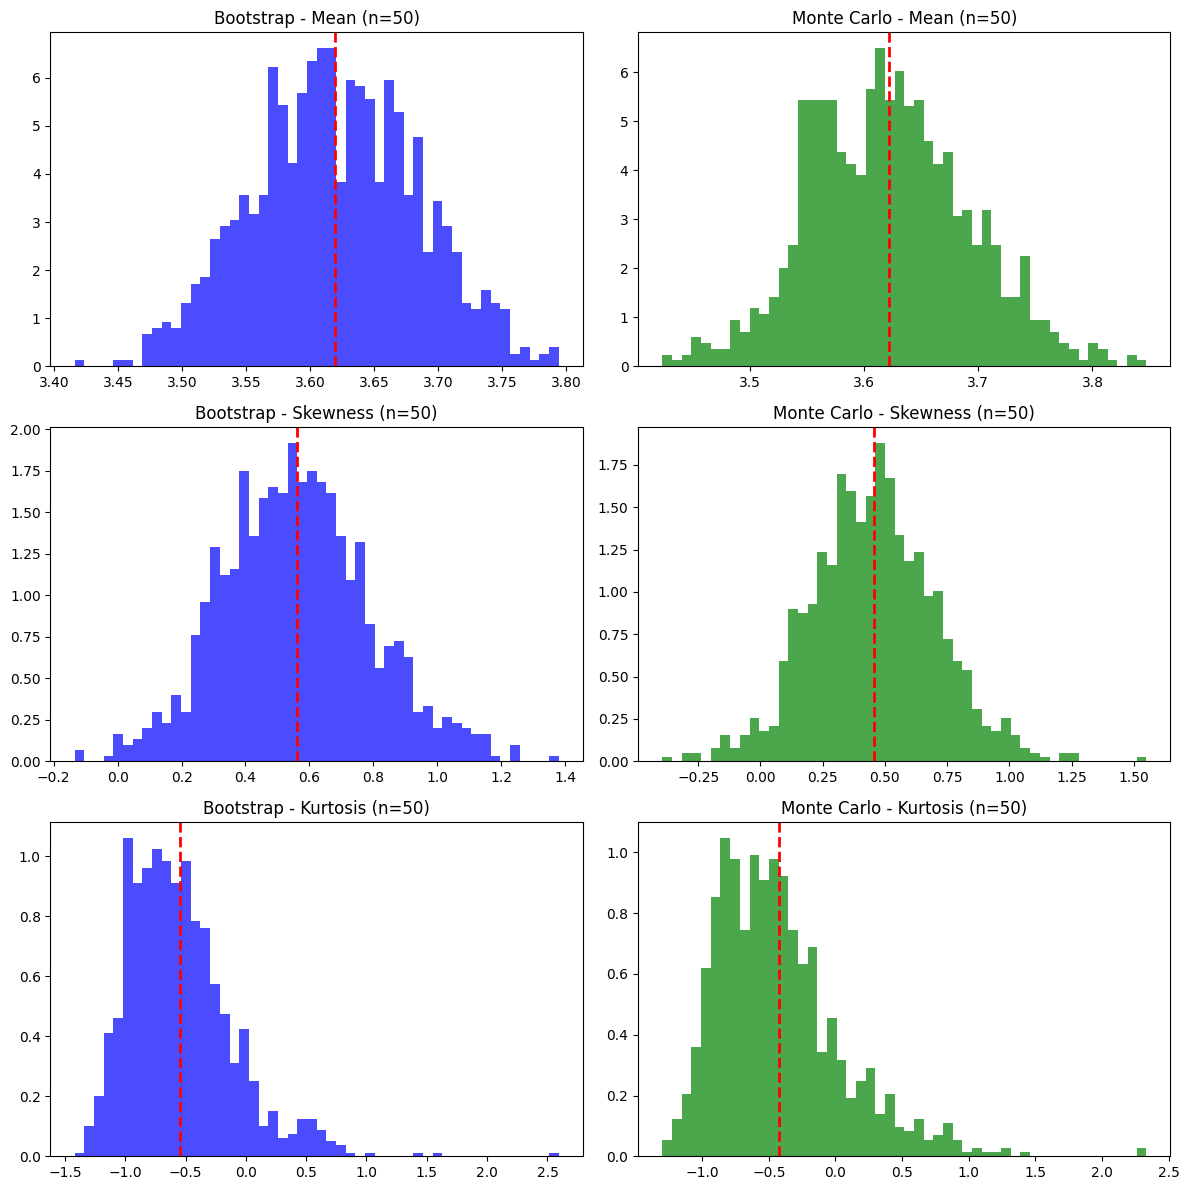


===== Resampling dengan ukuran 100 =====
Bootstrap - Estimator Mean: 3.619982, Variance Mean: 0.00209920488088088, Bias Mean: 0.0009703809523808893, MSE Mean: 0.002098047315192742
Monte Carlo - Estimator Mean: 3.6232767714937095, Variance Mean: 0.0024890971450830775, Bias Mean: 0.0023243905413288246, MSE Mean: 0.002492010839326615
Bootstrap - Estimator Skew: 0.5686837808202834, Variance Skew: 0.02414023678178569, Bias Skew: 0.005278423735870841, MSE Skew: 0.024143958302139307
Monte Carlo - Estimator Skew: 0.44680982000367603, Variance Skew: 0.030207150609842446, Bias Skew: 0.12715238455247818, MSE Skew: 0.0463446723566139
Bootstrap - Estimator Kurt: -0.5665895410037457, Variance Kurt: 0.07860460770080828, Bias Kurt: 0.007884663433155858, MSE Kurt: 0.0785881710105616
Monte Carlo - Estimator Kurt: -0.4399616345425024, Variance Kurt: 0.11188274248242318, Bias Kurt: 0.13451256989439914, MSE Kurt: 0.12986449119953639


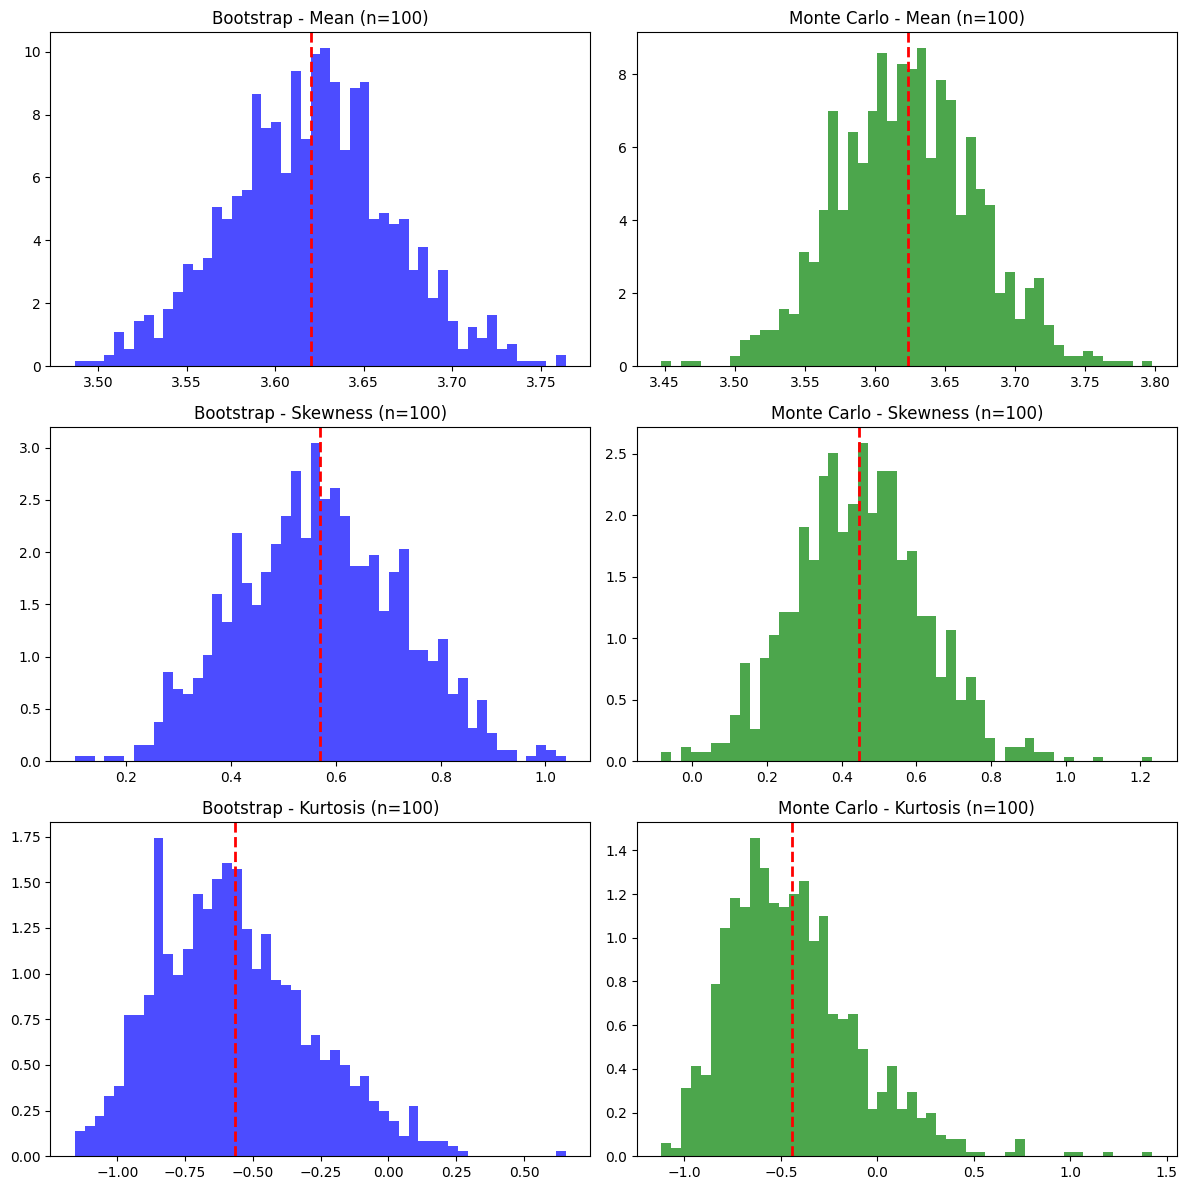


===== Resampling dengan ukuran 500 =====
Bootstrap - Estimator Mean: 3.6207756000000004, Variance Mean: 0.00041964224688688725, Bias Mean: 0.00017678095238027325, MSE Mean: 0.00041925385614512503
Monte Carlo - Estimator Mean: 3.6200610041791097, Variance Mean: 0.00047660953478118165, Bias Mean: 0.0008913767732710021, MSE Mean: 0.00047692747779832704
Bootstrap - Estimator Skew: 0.5732626037392025, Variance Skew: 0.004813735090576473, Bias Skew: 0.0006996008169517509, MSE Skew: 0.004809410796788976
Monte Carlo - Estimator Skew: 0.4627800930669143, Variance Skew: 0.005348688000835357, Bias Skew: 0.1111821114892399, MSE Skew: 0.017704801228040287
Bootstrap - Estimator Kurt: -0.56925326775808, Variance Kurt: 0.01696168484917091, Bias Kurt: 0.005220936678821508, MSE Kurt: 0.016971981344126
Monte Carlo - Estimator Kurt: -0.41983771454920327, Variance Kurt: 0.021183814087740675, Bias Kurt: 0.1546364898876983, MSE Kurt: 0.04507507427844115


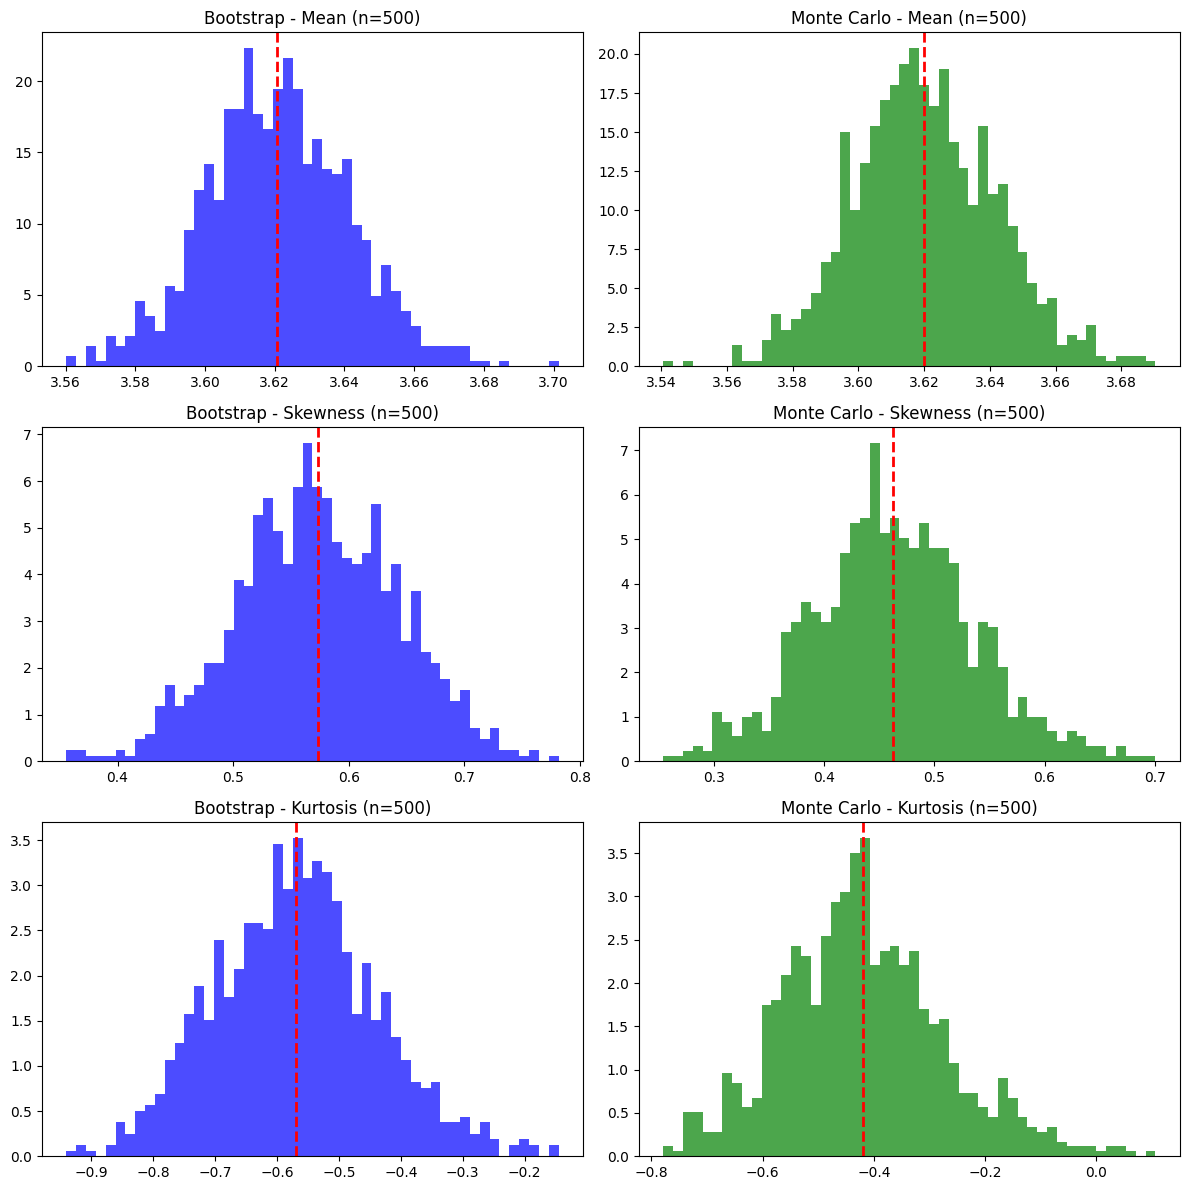


===== Resampling dengan ukuran 1000 =====
Bootstrap - Estimator Mean: 3.6212264999999997, Variance Mean: 0.0002099915593093091, Bias Mean: 0.0002741190476189814, MSE Mean: 0.00020985670900226753
Monte Carlo - Estimator Mean: 3.620433997637747, Variance Mean: 0.00024114406784864485, Bias Mean: 0.0005183833146338301, MSE Mean: 0.00024117164504168647
Bootstrap - Estimator Skew: 0.5730861537116821, Variance Skew: 0.002399771085815299, Bias Skew: 0.0008760508444720649, MSE Skew: 0.0023981387798115835
Monte Carlo - Estimator Skew: 0.461042408113902, Variance Skew: 0.0027153760852070977, Bias Skew: 0.1129197964422522, MSE Skew: 0.015463541137681561
Bootstrap - Estimator Kurt: -0.5710517571754005, Variance Kurt: 0.008300213641652312, Bias Kurt: 0.0034224472615010937, MSE Kurt: 0.008303626573268413
Monte Carlo - Estimator Kurt: -0.42718939953995083, Variance Kurt: 0.009734332516086422, Bias Kurt: 0.14728480489695073, MSE Kurt: 0.03141741193710317


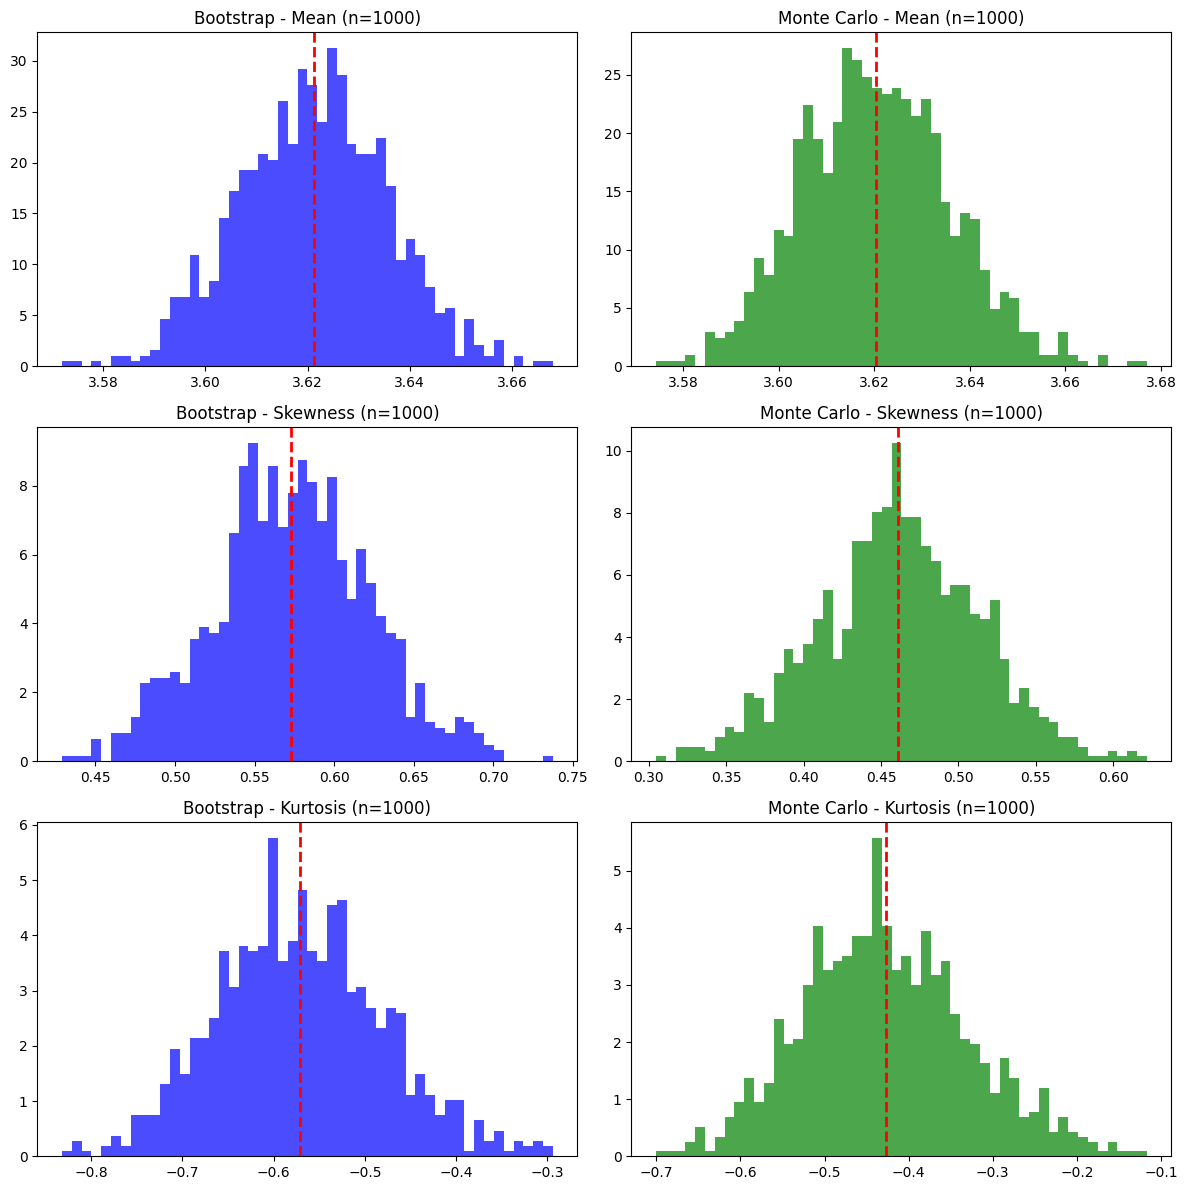

In [ ]:
# **1. Uji Normalitas Awal**
print("===== Uji Normalitas Data Asli =====")
shapiro_test = stats.shapiro(data)
ks_test = stats.kstest(data, 'norm', args=(np.mean(data), np.std(data)))

print(f"Shapiro-Wilk Test: p-value = {shapiro_test.pvalue}")
print(f"Kolmogorov-Smirnov Test: p-value = {ks_test.pvalue}")

# **2. Parameter Resampling**
sample_sizes = [50, 100, 500, 1000]
B = 1000  # Jumlah bootstrap/Monte Carlo iteration

# Simpan hasil
results = []

for n in sample_sizes:
    print(f"\n===== Resampling dengan ukuran {n} =====")

    # Simpan estimasi
    bootstrap_means = np.zeros(B)
    bootstrap_skew = np.zeros(B)
    bootstrap_kurt = np.zeros(B)

    mc_means = np.zeros(B)
    mc_skew = np.zeros(B)
    mc_kurt = np.zeros(B)

    # **3. Bootstrap Resampling**
    for i in range(B):
        resampled_data = np.random.choice(data, size=n, replace=True)
        bootstrap_means[i] = np.mean(resampled_data)
        bootstrap_skew[i] = stats.skew(resampled_data)
        bootstrap_kurt[i] = stats.kurtosis(resampled_data, fisher=True)

    # **4. Monte Carlo Resampling (dengan KDE)**
    kde = gaussian_kde(data)
    for i in range(B):
        mc_data = kde.resample(n)[0]
        mc_means[i] = np.mean(mc_data)
        mc_skew[i] = stats.skew(mc_data)
        mc_kurt[i] = stats.kurtosis(mc_data, fisher=True)

    # **5. Hitung Estimator, Varians, Bias, dan MSE**
    true_mean = np.mean(data)
    true_skew = stats.skew(data)
    true_kurt = stats.kurtosis(data, fisher=True)

    def calculate_metrics(estimates, true_value):
        estimator = np.mean(estimates)
        variance = np.var(estimates, ddof=1)  # ddof=1 untuk sample variance
        bias = np.abs(estimator - true_value)
        mse = np.mean((estimates - true_value) ** 2)
        return estimator, variance, bias, mse

    # Mean
    bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean = calculate_metrics(bootstrap_means, true_mean)
    mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean = calculate_metrics(mc_means, true_mean)

    # Skewness
    bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew = calculate_metrics(bootstrap_skew, true_skew)
    mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew = calculate_metrics(mc_skew, true_skew)

    # Kurtosis
    bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt = calculate_metrics(bootstrap_kurt, true_kurt)
    mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt = calculate_metrics(mc_kurt, true_kurt)

    print(f"Bootstrap - Estimator Mean: {bootstrap_est_mean}, Variance Mean: {bootstrap_var_mean}, Bias Mean: {bootstrap_bias_mean}, MSE Mean: {bootstrap_mse_mean}")
    print(f"Monte Carlo - Estimator Mean: {mc_est_mean}, Variance Mean: {mc_var_mean}, Bias Mean: {mc_bias_mean}, MSE Mean: {mc_mse_mean}")

    print(f"Bootstrap - Estimator Skew: {bootstrap_est_skew}, Variance Skew: {bootstrap_var_skew}, Bias Skew: {bootstrap_bias_skew}, MSE Skew: {bootstrap_mse_skew}")
    print(f"Monte Carlo - Estimator Skew: {mc_est_skew}, Variance Skew: {mc_var_skew}, Bias Skew: {mc_bias_skew}, MSE Skew: {mc_mse_skew}")

    print(f"Bootstrap - Estimator Kurt: {bootstrap_est_kurt}, Variance Kurt: {bootstrap_var_kurt}, Bias Kurt: {bootstrap_bias_kurt}, MSE Kurt: {bootstrap_mse_kurt}")
    print(f"Monte Carlo - Estimator Kurt: {mc_est_kurt}, Variance Kurt: {mc_var_kurt}, Bias Kurt: {mc_bias_kurt}, MSE Kurt: {mc_mse_kurt}")

    # **6. Simpan Hasil**
    results.append([n, "Bootstrap", "Mean", bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean])
    results.append([n, "Monte Carlo", "Mean", mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean])
    results.append([n, "Bootstrap", "Skewness", bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew])
    results.append([n, "Monte Carlo", "Skewness", mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew])
    results.append([n, "Bootstrap", "Kurtosis", bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt])
    results.append([n, "Monte Carlo", "Kurtosis", mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt])

    # **7. Plot Histogram & Kurva Kepadatan Normal**
    fig, axs = plt.subplots(3, 2, figsize=(12, 12))

    # Mean
    axs[0, 0].hist(bootstrap_means, bins=50, color='b', alpha=0.7, density=True)
    axs[0, 0].axvline(bootstrap_est_mean, color='r', linestyle='dashed', linewidth=2)
    axs[0, 0].set_title(f"Bootstrap - Mean (n={n})")

    axs[0, 1].hist(mc_means, bins=50, color='g', alpha=0.7, density=True)
    axs[0, 1].axvline(mc_est_mean, color='r', linestyle='dashed', linewidth=2)
    axs[0, 1].set_title(f"Monte Carlo - Mean (n={n})")

    # Skewness
    axs[1, 0].hist(bootstrap_skew, bins=50, color='b', alpha=0.7, density=True)
    axs[1, 0].axvline(bootstrap_est_skew, color='r', linestyle='dashed', linewidth=2)
    axs[1, 0].set_title(f"Bootstrap - Skewness (n={n})")

    axs[1, 1].hist(mc_skew, bins=50, color='g', alpha=0.7, density=True)
    axs[1, 1].axvline(mc_est_skew, color='r', linestyle='dashed', linewidth=2)
    axs[1, 1].set_title(f"Monte Carlo - Skewness (n={n})")

    # Kurtosis
    axs[2, 0].hist(bootstrap_kurt, bins=50, color='b', alpha=0.7, density=True)
    axs[2, 0].axvline(bootstrap_est_kurt, color='r', linestyle='dashed', linewidth=2)
    axs[2, 0].set_title(f"Bootstrap - Kurtosis (n={n})")

    axs[2, 1].hist(mc_kurt, bins=50, color='g', alpha=0.7, density=True)
    axs[2, 1].axvline(mc_est_kurt, color='r', linestyle='dashed', linewidth=2)
    axs[2, 1].set_title(f"Monte Carlo - Kurtosis (n={n})")

    plt.tight_layout()
    plt.show()


In [ ]:
from prettytable import PrettyTable

# **9. Membuat DataFrame Hasil Perbandingan**
df_results = pd.DataFrame(results, columns=["Sample Size", "Method", "Metric", "Estimator", "Variance", "Bias", "MSE"])

# **10. Inisialisasi PrettyTable**
table = PrettyTable()
table.field_names = ["Sample Size", "Metric", "Method", "Estimator", "Variance", "Bias", "MSE"]

# **11. Menambahkan Data ke PrettyTable**
for _, row in df_results.iterrows():
    table.add_row([row["Sample Size"], row["Metric"], row["Method"],
                   f"{row['Estimator']:.4f}", f"{row['Variance']:.4f}",
                   f"{row['Bias']:.4f}", f"{row['MSE']:.4f}"])

# **12. Menampilkan Hasil dalam Bentuk Tabel**
table.align = "c"  # Rata tengah
print("\n===== Tabel Perbandingan Estimator, Variance, Bias, dan MSE =====")
print(table)




===== Tabel Perbandingan Estimator, Variance, Bias, dan MSE =====
+-------------+----------+-------------+-----------+----------+--------+--------+
| Sample Size |  Metric  |    Method   | Estimator | Variance |  Bias  |  MSE   |
+-------------+----------+-------------+-----------+----------+--------+--------+
|      50     |   Mean   |  Bootstrap  |   3.6195  |  0.0041  | 0.0015 | 0.0041 |
|      50     |   Mean   | Monte Carlo |   3.6215  |  0.0049  | 0.0005 | 0.0049 |
|      50     | Skewness |  Bootstrap  |   0.5606  |  0.0531  | 0.0133 | 0.0533 |
|      50     | Skewness | Monte Carlo |   0.4546  |  0.0625  | 0.1194 | 0.0766 |
|      50     | Kurtosis |  Bootstrap  |  -0.5453  |  0.1887  | 0.0292 | 0.1893 |
|      50     | Kurtosis | Monte Carlo |  -0.4268  |  0.2235  | 0.1476 | 0.2451 |
|     100     |   Mean   |  Bootstrap  |   3.6200  |  0.0021  | 0.0010 | 0.0021 |
|     100     |   Mean   | Monte Carlo |   3.6233  |  0.0025  | 0.0023 | 0.0025 |
|     100     | Skewness |  Boo

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from statsmodels.graphics.gofplots import qqplot
from prettytable import PrettyTable

# **1. Load Data Gempa Bumi**
data = pd.read_excel('/content/Data Gempa Bumi.xlsx')
data = data.values.flatten()

# **2. Uji Normalitas Awal**
print("===== Uji Normalitas Data Asli =====")
shapiro_test = stats.shapiro(data)
ks_test = stats.kstest(data, 'norm', args=(np.mean(data), np.std(data)))

print(f"Shapiro-Wilk Test: p-value = {shapiro_test.pvalue}")
print(f"Kolmogorov-Smirnov Test: p-value = {ks_test.pvalue}")

# **3. Parameter Resampling**
sample_sizes = [50, 100, 500, 1000]
B = 1000  # Jumlah bootstrap/Monte Carlo iteration

# Simpan hasil
results = []

for n in sample_sizes:
    print(f"\n===== Resampling dengan ukuran {n} =====")

    # Simpan estimasi
    bootstrap_means = np.zeros(B)
    bootstrap_skew = np.zeros(B)
    bootstrap_kurt = np.zeros(B)

    mc_means = np.zeros(B)
    mc_skew = np.zeros(B)
    mc_kurt = np.zeros(B)

    # **4. Bootstrap Resampling**
    for i in range(B):
        resampled_data = np.random.choice(data, size=n, replace=True)
        bootstrap_means[i] = np.mean(resampled_data)
        bootstrap_skew[i] = stats.skew(resampled_data)
        bootstrap_kurt[i] = stats.kurtosis(resampled_data, fisher=True)

    # **5. Monte Carlo Resampling (dengan KDE)**
    kde = gaussian_kde(data)
    for i in range(B):
        mc_data = kde.resample(n)[0]
        mc_means[i] = np.mean(mc_data)
        mc_skew[i] = stats.skew(mc_data)
        mc_kurt[i] = stats.kurtosis(mc_data, fisher=True)

    # **6. Hitung Estimator, Varians, Bias, dan MSE**
    true_mean = np.mean(data)
    true_skew = stats.skew(data)
    true_kurt = stats.kurtosis(data, fisher=True)

    def calculate_metrics(estimates, true_value):
        estimator = np.mean(estimates)
        variance = np.var(estimates, ddof=1)  # ddof=1 untuk sample variance
        bias = np.abs(estimator - true_value)
        mse = np.mean((estimates - true_value) ** 2)
        return estimator, variance, bias, mse

    # **Mean**
    bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean = calculate_metrics(bootstrap_means, true_mean)
    mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean = calculate_metrics(mc_means, true_mean)

    # **Skewness**
    bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew = calculate_metrics(bootstrap_skew, true_skew)
    mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew = calculate_metrics(mc_skew, true_skew)

    # **Kurtosis**
    bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt = calculate_metrics(bootstrap_kurt, true_kurt)
    mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt = calculate_metrics(mc_kurt, true_kurt)

    # **7. Simpan Hasil**
    results.append([n, "Bootstrap", "Mean", bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean])
    results.append([n, "Monte Carlo", "Mean", mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean])
    results.append([n, "Bootstrap", "Skewness", bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew])
    results.append([n, "Monte Carlo", "Skewness", mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew])
    results.append([n, "Bootstrap", "Kurtosis", bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt])
    results.append([n, "Monte Carlo", "Kurtosis", mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt])

# **8. Membuat DataFrame Hasil Perbandingan**
df_results = pd.DataFrame(results, columns=["Sample Size", "Method", "Metric", "Estimator", "Variance", "Bias", "MSE"])

# **9. Inisialisasi PrettyTable untuk Mean, Skewness, Kurtosis**
table = PrettyTable()
table.field_names = ["Sample Size", "Metric", "Method", "Estimator", "Variance", "Bias", "MSE"]

for _, row in df_results.iterrows():
    table.add_row([row["Sample Size"], row["Metric"], row["Method"],
                   f"{row['Estimator']:.4f}", f"{row['Variance']:.4f}",
                   f"{row['Bias']:.4f}", f"{row['MSE']:.4f}"])

print("\n===== Tabel Perbandingan Estimator, Variance, Bias, dan MSE =====")
print(table)

# **10. Menampilkan Tabel Khusus untuk Skewness dan Kurtosis**
table_skew_kurt = PrettyTable()
table_skew_kurt.field_names = ["Sample Size", "Method", "Metric", "Estimator", "Variance"]

for _, row in df_results.iterrows():
    if row["Metric"] in ["Skewness", "Kurtosis"]:
        table_skew_kurt.add_row([row["Sample Size"], row["Method"], row["Metric"],
                                 f"{row['Estimator']:.4f}", f"{row['Variance']:.4f}"])

print("\n===== Tabel Estimasi Skewness dan Kurtosis =====")
print(table_skew_kurt)


===== Uji Normalitas Data Asli =====
Shapiro-Wilk Test: p-value = 0.00010690115922114884
Kolmogorov-Smirnov Test: p-value = 0.07280294123823779

===== Resampling dengan ukuran 50 =====

===== Resampling dengan ukuran 100 =====

===== Resampling dengan ukuran 500 =====

===== Resampling dengan ukuran 1000 =====

===== Tabel Perbandingan Estimator, Variance, Bias, dan MSE =====
+-------------+----------+-------------+-----------+----------+--------+--------+
| Sample Size |  Metric  |    Method   | Estimator | Variance |  Bias  |  MSE   |
+-------------+----------+-------------+-----------+----------+--------+--------+
|      50     |   Mean   |  Bootstrap  |   3.6137  |  0.0043  | 0.0014 | 0.0043 |
|      50     |   Mean   | Monte Carlo |   3.6170  |  0.0047  | 0.0019 | 0.0047 |
|      50     | Skewness |  Bootstrap  |   0.5607  |  0.0501  | 0.0157 | 0.0503 |
|      50     | Skewness | Monte Carlo |   0.4383  |  0.0559  | 0.1381 | 0.0749 |
|      50     | Kurtosis |  Bootstrap  |  -0.54

In [2]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from statsmodels.graphics.gofplots import qqplot
from prettytable import PrettyTable

# **1. Load Data Gempa Bumi**
data = pd.read_excel('/content/Data Gempa Bumi.xlsx')
data = data.values.flatten()

# **2. Uji Normalitas Awal**
print("===== Uji Normalitas Data Asli =====")
shapiro_test = stats.shapiro(data)
ks_test = stats.kstest(data, 'norm', args=(np.mean(data), np.std(data)))

print(f"Shapiro-Wilk Test: p-value = {shapiro_test.pvalue}")
print(f"Kolmogorov-Smirnov Test: p-value = {ks_test.pvalue}")

# **3. Parameter Resampling**
sample_sizes = [50, 100, 500, 1000]
B = 1000  # Jumlah bootstrap/Monte Carlo iteration

# Simpan hasil
results_mean = []
results_skew = []
results_kurt = []

for n in sample_sizes:
    print(f"\n===== Resampling dengan ukuran {n} =====")

    # Simpan estimasi
    bootstrap_means = np.zeros(B)
    bootstrap_skew = np.zeros(B)
    bootstrap_kurt = np.zeros(B)

    mc_means = np.zeros(B)
    mc_skew = np.zeros(B)
    mc_kurt = np.zeros(B)

    # **4. Bootstrap Resampling**
    for i in range(B):
        resampled_data = np.random.choice(data, size=n, replace=True)
        bootstrap_means[i] = np.mean(resampled_data)
        bootstrap_skew[i] = stats.skew(resampled_data)
        bootstrap_kurt[i] = stats.kurtosis(resampled_data, fisher=True)

    # **5. Monte Carlo Resampling (dengan KDE)**
    kde = gaussian_kde(data)
    for i in range(B):
        mc_data = kde.resample(n)[0]
        mc_means[i] = np.mean(mc_data)
        mc_skew[i] = stats.skew(mc_data)
        mc_kurt[i] = stats.kurtosis(mc_data, fisher=True)

    # **6. Hitung Estimator, Varians, Bias, dan MSE**
    true_mean = np.mean(data)
    true_skew = stats.skew(data)
    true_kurt = stats.kurtosis(data, fisher=True)

    def calculate_metrics(estimates, true_value):
        estimator = np.mean(estimates)
        variance = np.var(estimates, ddof=1)  # ddof=1 untuk sample variance
        bias = np.abs(estimator - true_value)
        mse = np.mean((estimates - true_value) ** 2)
        return estimator, variance, bias, mse

    # **Mean**
    bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean = calculate_metrics(bootstrap_means, true_mean)
    mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean = calculate_metrics(mc_means, true_mean)

    # **Skewness**
    bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew = calculate_metrics(bootstrap_skew, true_skew)
    mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew = calculate_metrics(mc_skew, true_skew)

    # **Kurtosis**
    bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt = calculate_metrics(bootstrap_kurt, true_kurt)
    mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt = calculate_metrics(mc_kurt, true_kurt)

    # **7. Simpan Hasil ke List yang Sesuai**
    results_mean.append([n, "Bootstrap", bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean])
    results_mean.append([n, "Monte Carlo", mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean])

    results_skew.append([n, "Bootstrap", bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew])
    results_skew.append([n, "Monte Carlo", mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew])

    results_kurt.append([n, "Bootstrap", bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt])
    results_kurt.append([n, "Monte Carlo", mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt])

# **8. Membuat dan Menampilkan Tabel Mean**
table_mean = PrettyTable()
table_mean.field_names = ["Sample Size", "Method", "Estimator", "Variance", "Bias", "MSE"]

for row in results_mean:
    table_mean.add_row([row[0], row[1], f"{row[2]:.4f}", f"{row[3]:.4f}", f"{row[4]:.4f}", f"{row[5]:.4f}"])

print("\n===== Tabel Perbandingan Estimator Mean =====")
print(table_mean)

# **9. Membuat dan Menampilkan Tabel Skewness**
table_skew = PrettyTable()
table_skew.field_names = ["Sample Size", "Method", "Estimator", "Variance", "Bias", "MSE"]

for row in results_skew:
    table_skew.add_row([row[0], row[1], f"{row[2]:.4f}", f"{row[3]:.4f}", f"{row[4]:.4f}", f"{row[5]:.4f}"])

print("\n===== Tabel Perbandingan Estimator Skewness =====")
print(table_skew)

# **10. Membuat dan Menampilkan Tabel Kurtosis**
table_kurt = PrettyTable()
table_kurt.field_names = ["Sample Size", "Method", "Estimator", "Variance", "Bias", "MSE"]

for row in results_kurt:
    table_kurt.add_row([row[0], row[1], f"{row[2]:.4f}", f"{row[3]:.4f}", f"{row[4]:.4f}", f"{row[5]:.4f}"])

print("\n===== Tabel Perbandingan Estimator Kurtosis =====")
print(table_kurt)


===== Uji Normalitas Data Asli =====
Shapiro-Wilk Test: p-value = 0.00010690115922114884
Kolmogorov-Smirnov Test: p-value = 0.07280294123823779

===== Resampling dengan ukuran 50 =====

===== Resampling dengan ukuran 100 =====

===== Resampling dengan ukuran 500 =====

===== Resampling dengan ukuran 1000 =====

===== Tabel Perbandingan Estimator Mean =====
+-------------+-------------+-----------+----------+--------+--------+
| Sample Size |    Method   | Estimator | Variance |  Bias  |  MSE   |
+-------------+-------------+-----------+----------+--------+--------+
|      50     |  Bootstrap  |   3.6179  |  0.0043  | 0.0028 | 0.0043 |
|      50     | Monte Carlo |   3.6151  |  0.0045  | 0.0000 | 0.0045 |
|     100     |  Bootstrap  |   3.6157  |  0.0021  | 0.0006 | 0.0021 |
|     100     | Monte Carlo |   3.6143  |  0.0023  | 0.0008 | 0.0023 |
|     500     |  Bootstrap  |   3.6142  |  0.0004  | 0.0009 | 0.0004 |
|     500     | Monte Carlo |   3.6157  |  0.0005  | 0.0006 | 0.0005 |
| 

In [3]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from prettytable import PrettyTable

# **1. Load Data Gempa Bumi**
data = pd.read_excel('/content/Data Gempa Bumi.xlsx')
data = data.values.flatten()

# **2. Parameter Resampling**
sample_sizes = [50, 100, 500, 1000]
B = 1000  # Jumlah bootstrap/Monte Carlo iteration

# Simpan hasil dalam tabel terpisah
results_bootstrap_mean = []
results_mc_mean = []

results_bootstrap_skew = []
results_mc_skew = []

results_bootstrap_kurt = []
results_mc_kurt = []

for n in sample_sizes:
    print(f"\n===== Resampling dengan ukuran {n} =====")

    # Simpan estimasi
    bootstrap_means = np.zeros(B)
    bootstrap_skew = np.zeros(B)
    bootstrap_kurt = np.zeros(B)

    mc_means = np.zeros(B)
    mc_skew = np.zeros(B)
    mc_kurt = np.zeros(B)

    # **3. Bootstrap Resampling**
    for i in range(B):
        resampled_data = np.random.choice(data, size=n, replace=True)
        bootstrap_means[i] = np.mean(resampled_data)
        bootstrap_skew[i] = stats.skew(resampled_data)
        bootstrap_kurt[i] = stats.kurtosis(resampled_data, fisher=True)

    # **4. Monte Carlo Resampling (dengan KDE)**
    kde = gaussian_kde(data)
    for i in range(B):
        mc_data = kde.resample(n)[0]
        mc_means[i] = np.mean(mc_data)
        mc_skew[i] = stats.skew(mc_data)
        mc_kurt[i] = stats.kurtosis(mc_data, fisher=True)

    # **5. Hitung Estimator, Varians, Bias, dan MSE**
    true_mean = np.mean(data)
    true_skew = stats.skew(data)
    true_kurt = stats.kurtosis(data, fisher=True)

    def calculate_metrics(estimates, true_value):
        estimator = np.mean(estimates)
        variance = np.var(estimates, ddof=1)
        bias = np.abs(estimator - true_value)
        mse = np.mean((estimates - true_value) ** 2)
        return estimator, variance, bias, mse

    # **Bootstrap Metrics**
    bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean = calculate_metrics(bootstrap_means, true_mean)
    bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew = calculate_metrics(bootstrap_skew, true_skew)
    bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt = calculate_metrics(bootstrap_kurt, true_kurt)

    # **Monte Carlo Metrics**
    mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean = calculate_metrics(mc_means, true_mean)
    mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew = calculate_metrics(mc_skew, true_skew)
    mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt = calculate_metrics(mc_kurt, true_kurt)

    # **6. Simpan Hasil ke Tabel Sesuai Metode**
    results_bootstrap_mean.append([n, bootstrap_est_mean, bootstrap_var_mean, bootstrap_bias_mean, bootstrap_mse_mean])
    results_mc_mean.append([n, mc_est_mean, mc_var_mean, mc_bias_mean, mc_mse_mean])

    results_bootstrap_skew.append([n, bootstrap_est_skew, bootstrap_var_skew, bootstrap_bias_skew, bootstrap_mse_skew])
    results_mc_skew.append([n, mc_est_skew, mc_var_skew, mc_bias_skew, mc_mse_skew])

    results_bootstrap_kurt.append([n, bootstrap_est_kurt, bootstrap_var_kurt, bootstrap_bias_kurt, bootstrap_mse_kurt])
    results_mc_kurt.append([n, mc_est_kurt, mc_var_kurt, mc_bias_kurt, mc_mse_kurt])

# **7. Fungsi untuk Membuat dan Menampilkan Tabel**
def print_table(title, results):
    table = PrettyTable()
    table.field_names = ["Sample Size", "Estimator", "Variance", "Bias", "MSE"]
    for row in results:
        table.add_row([row[0], f"{row[1]:.4f}", f"{row[2]:.4f}", f"{row[3]:.4f}", f"{row[4]:.4f}"])
    print(f"\n===== {title} =====")
    print(table)

# **8. Cetak Semua Tabel Terpisah**
print_table("Estimator Mean (Bootstrap)", results_bootstrap_mean)
print_table("Estimator Mean (Monte Carlo)", results_mc_mean)

print_table("Estimator Skewness (Bootstrap)", results_bootstrap_skew)
print_table("Estimator Skewness (Monte Carlo)", results_mc_skew)

print_table("Estimator Kurtosis (Bootstrap)", results_bootstrap_kurt)
print_table("Estimator Kurtosis (Monte Carlo)", results_mc_kurt)



===== Resampling dengan ukuran 50 =====

===== Resampling dengan ukuran 100 =====

===== Resampling dengan ukuran 500 =====

===== Resampling dengan ukuran 1000 =====

===== Estimator Mean (Bootstrap) =====
+-------------+-----------+----------+--------+--------+
| Sample Size | Estimator | Variance |  Bias  |  MSE   |
+-------------+-----------+----------+--------+--------+
|      50     |   3.6109  |  0.0040  | 0.0042 | 0.0040 |
|     100     |   3.6138  |  0.0020  | 0.0013 | 0.0020 |
|     500     |   3.6156  |  0.0004  | 0.0005 | 0.0004 |
|     1000    |   3.6146  |  0.0002  | 0.0005 | 0.0002 |
+-------------+-----------+----------+--------+--------+

===== Estimator Mean (Monte Carlo) =====
+-------------+-----------+----------+--------+--------+
| Sample Size | Estimator | Variance |  Bias  |  MSE   |
+-------------+-----------+----------+--------+--------+
|      50     |   3.6150  |  0.0051  | 0.0001 | 0.0051 |
|     100     |   3.6125  |  0.0023  | 0.0026 | 0.0023 |
|     500


===== Resampling dengan ukuran 50 =====


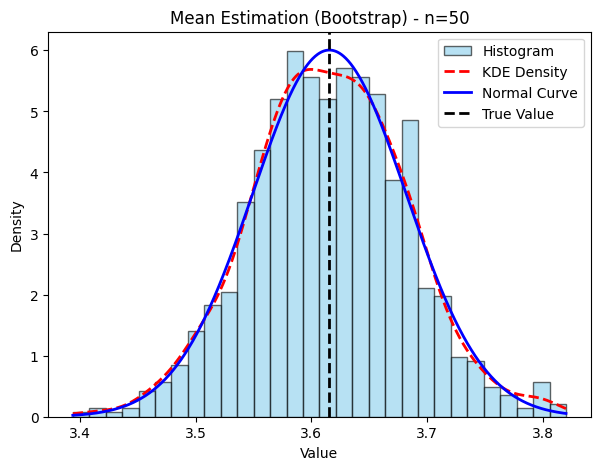

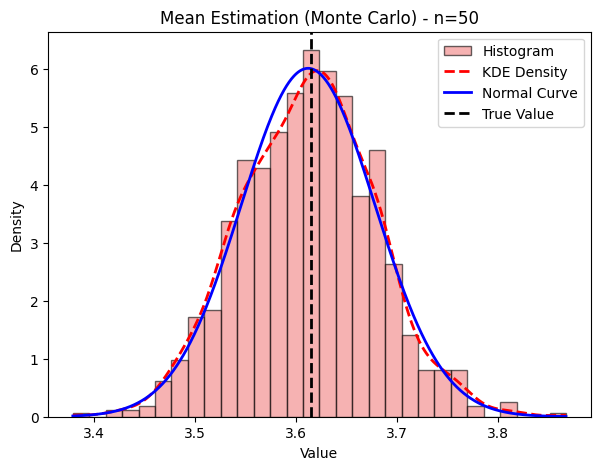

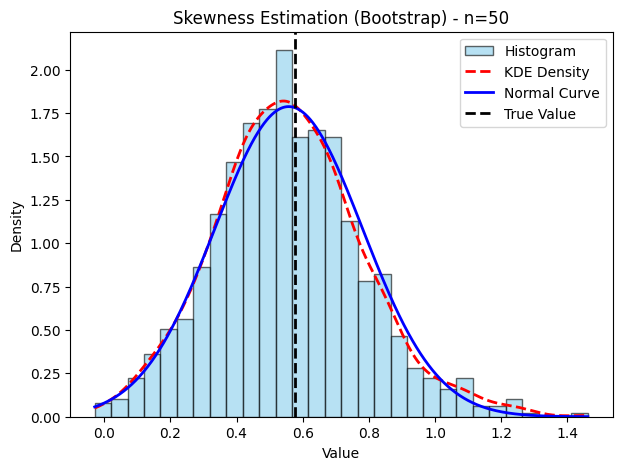

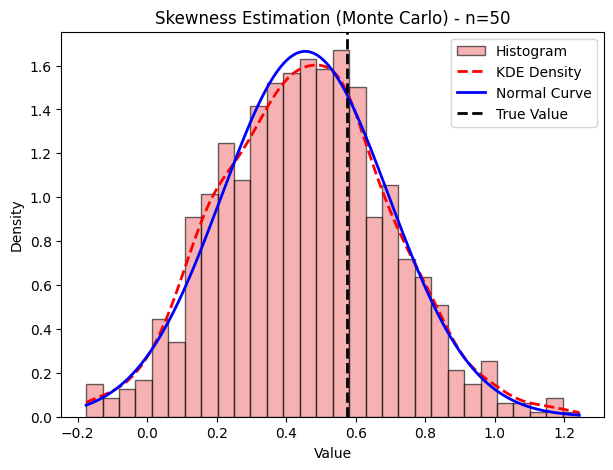

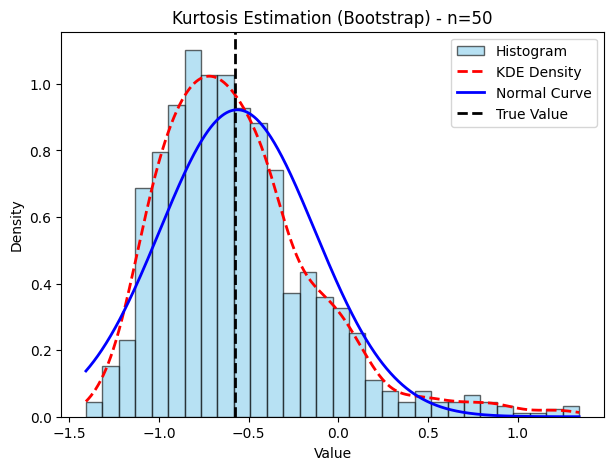

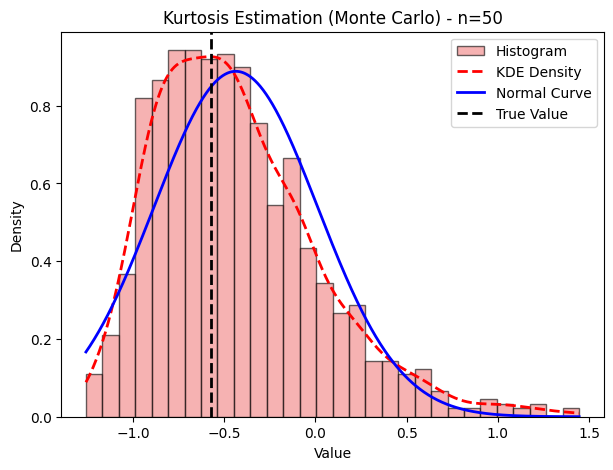


===== Resampling dengan ukuran 100 =====


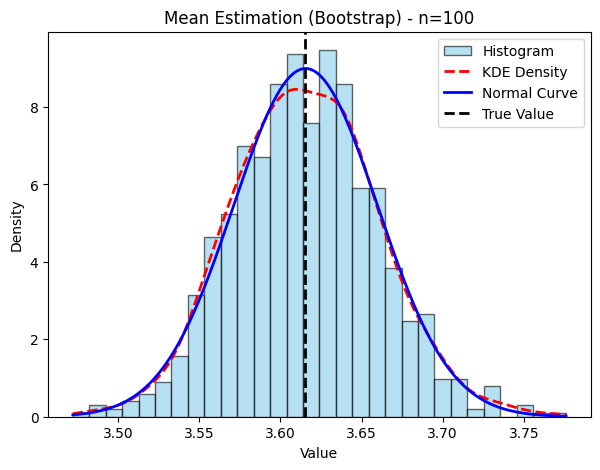

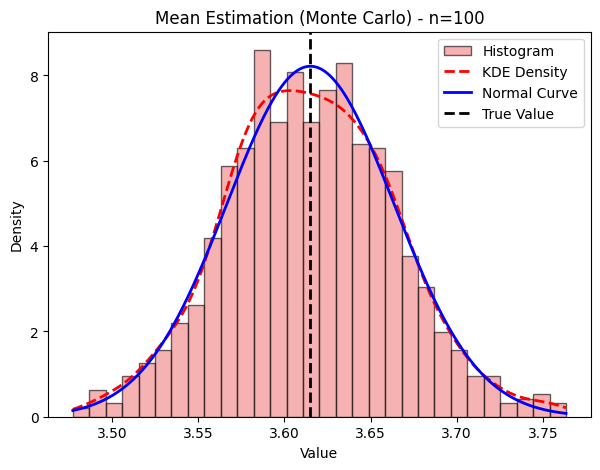

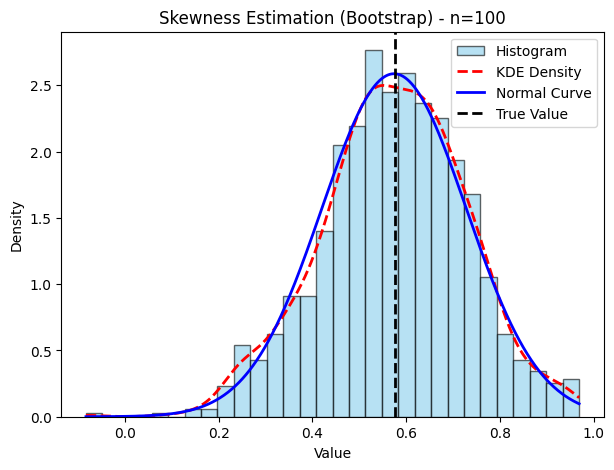

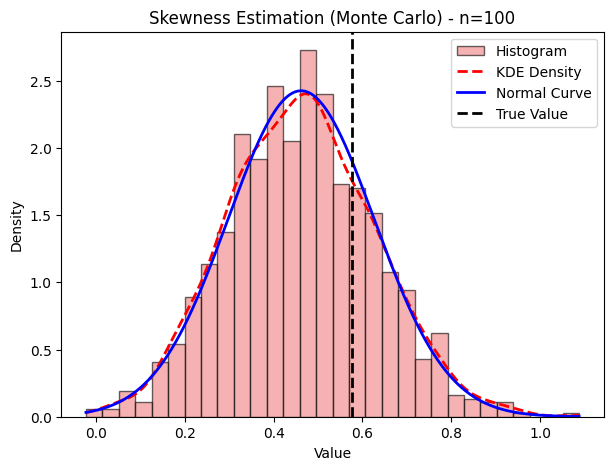

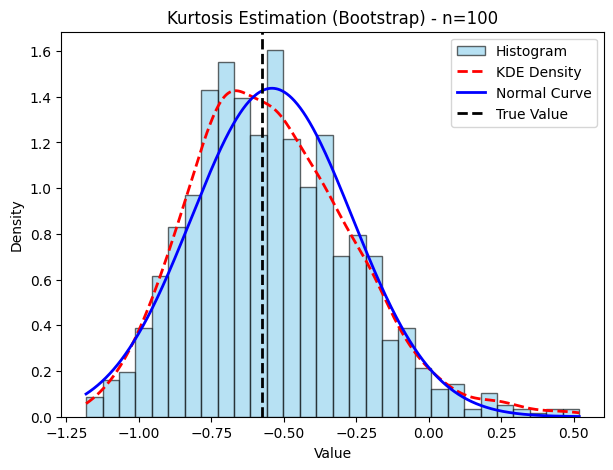

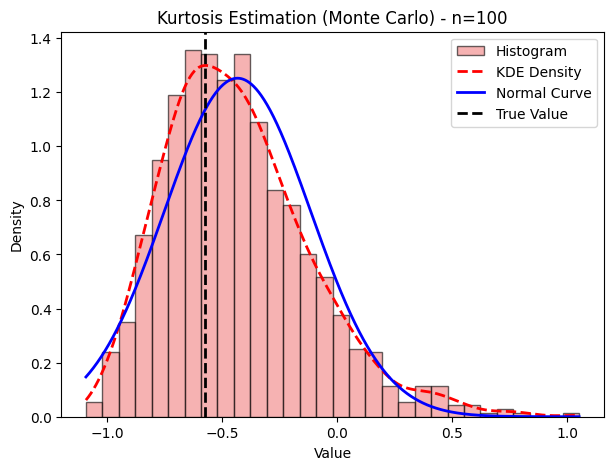


===== Resampling dengan ukuran 500 =====


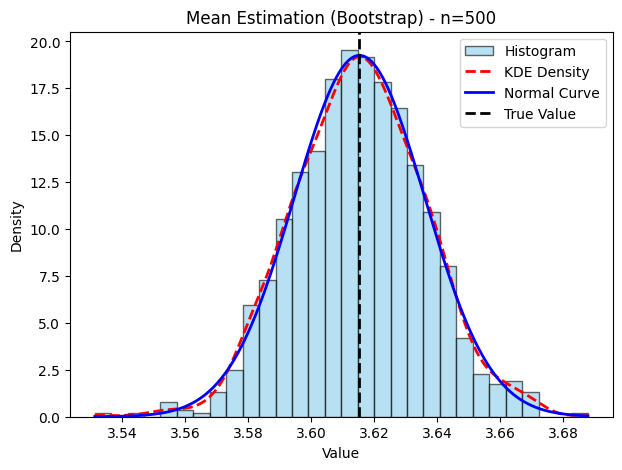

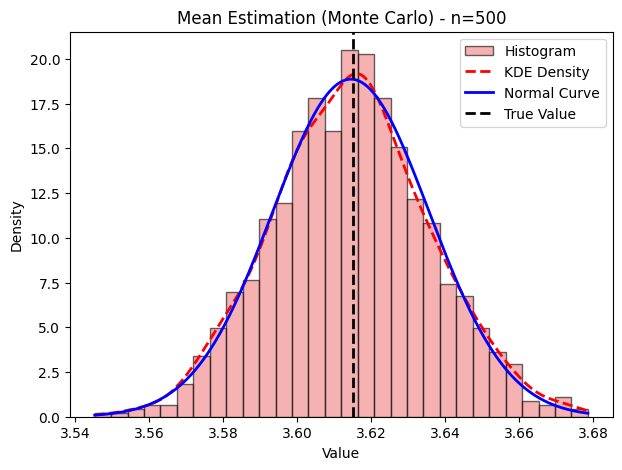

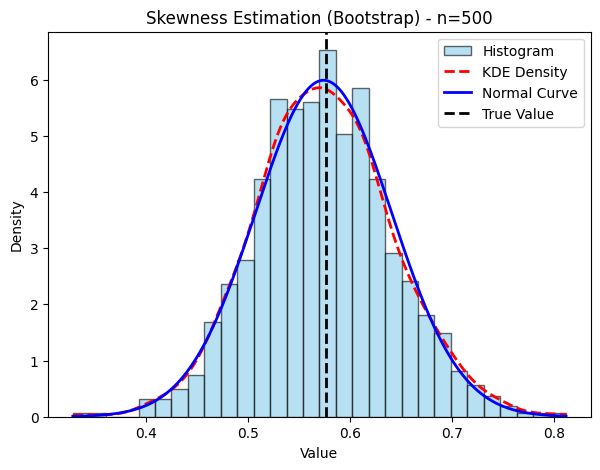

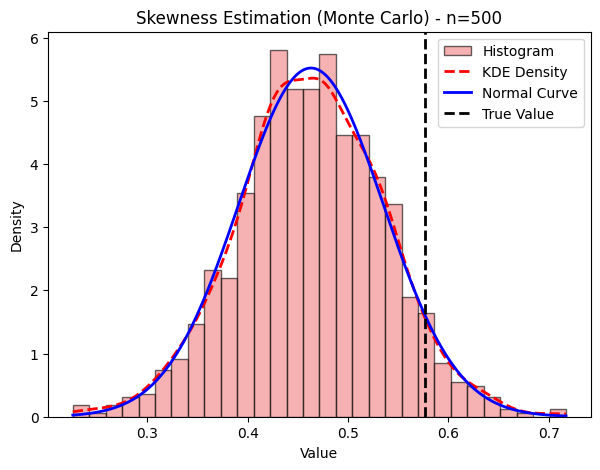

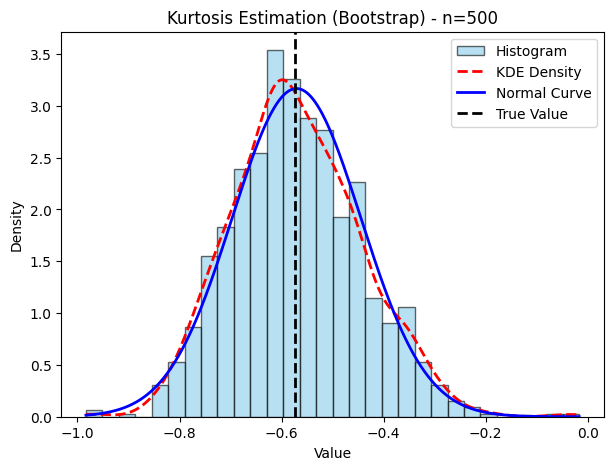

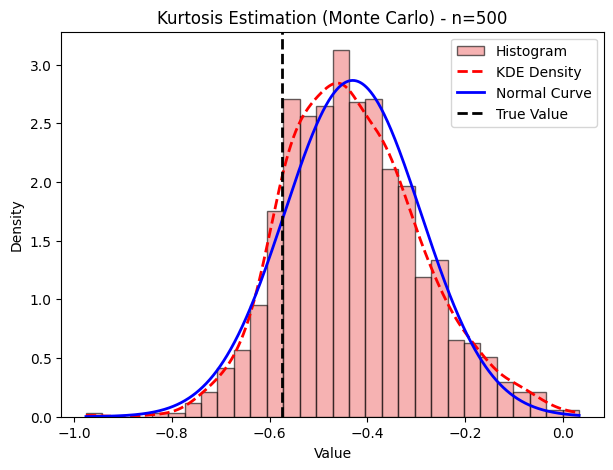


===== Resampling dengan ukuran 1000 =====


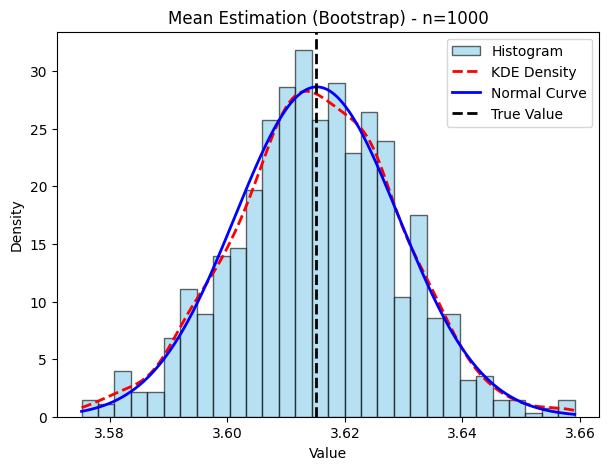

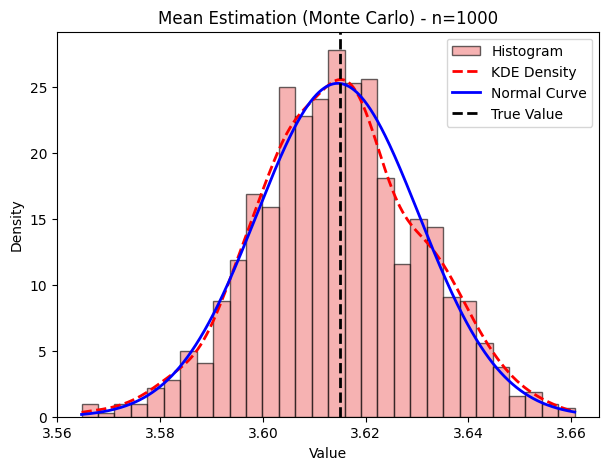

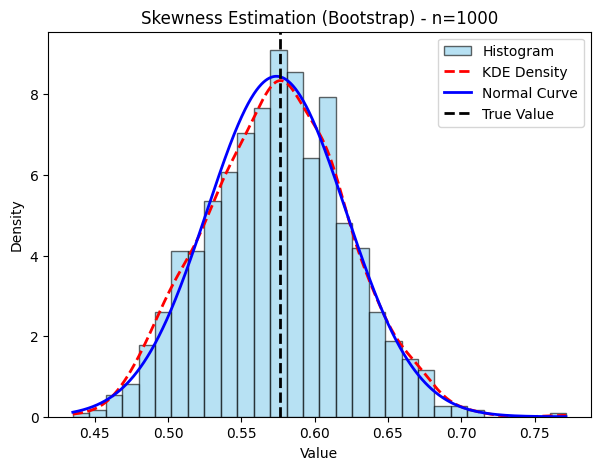

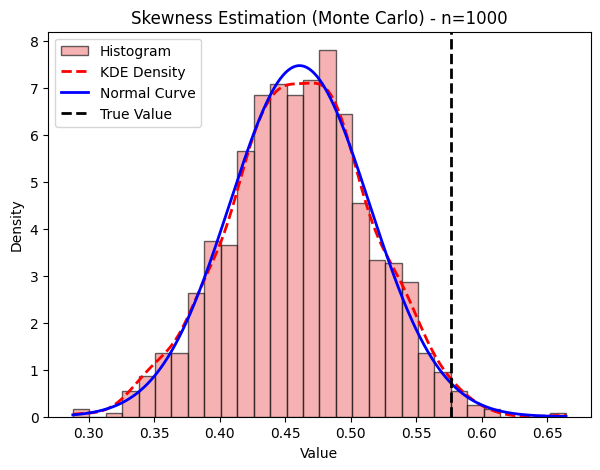

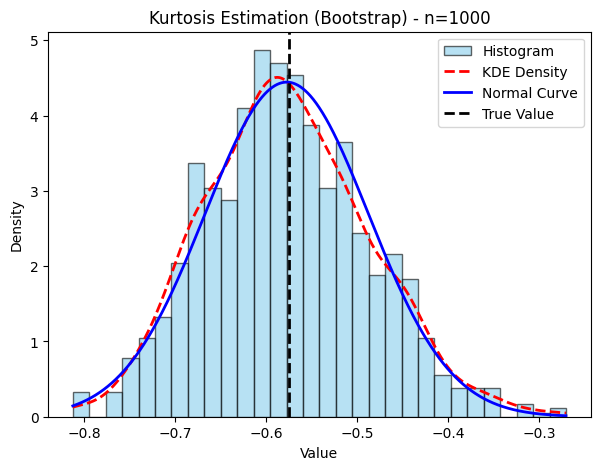

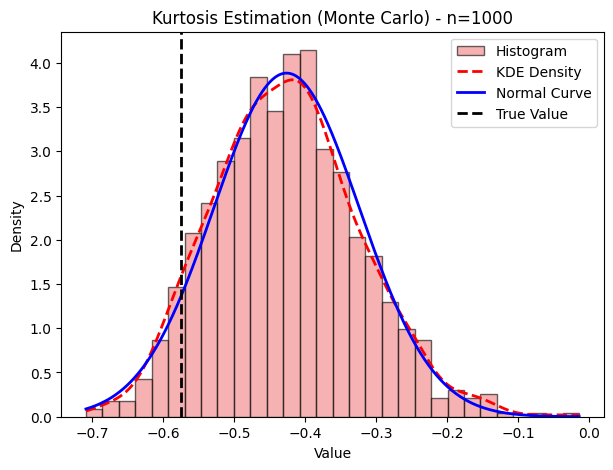

In [4]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from prettytable import PrettyTable

# **1. Load Data Gempa Bumi**
data = pd.read_excel('/content/Data Gempa Bumi.xlsx')
data = data.values.flatten()

# **2. Parameter Resampling**
sample_sizes = [50, 100, 500, 1000]
B = 1000  # Jumlah bootstrap/Monte Carlo iteration

# **3. Fungsi untuk Membuat Histogram dan Kurva Kepadatan**
def plot_hist_density(estimates, true_value, title, color):
    plt.figure(figsize=(7, 5))
    plt.hist(estimates, bins=30, density=True, alpha=0.6, color=color, edgecolor="black", label="Histogram")

    # Kurva kepadatan kernel (KDE)
    kde = gaussian_kde(estimates)
    x_vals = np.linspace(min(estimates), max(estimates), 1000)
    plt.plot(x_vals, kde(x_vals), color="red", linestyle="--", linewidth=2, label="KDE Density")

    # Kurva distribusi normal dengan rata-rata dan standar deviasi dari hasil estimasi
    mean, std = np.mean(estimates), np.std(estimates)
    normal_dist = stats.norm.pdf(x_vals, mean, std)
    plt.plot(x_vals, normal_dist, color="blue", linewidth=2, label="Normal Curve")

    # Garis vertikal nilai sebenarnya
    plt.axvline(true_value, color="black", linestyle="dashed", linewidth=2, label="True Value")

    plt.title(title)
    plt.xlabel("Value")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

# **4. Simulasi Resampling**
for n in sample_sizes:
    print(f"\n===== Resampling dengan ukuran {n} =====")

    # Simpan estimasi
    bootstrap_means = np.zeros(B)
    bootstrap_skew = np.zeros(B)
    bootstrap_kurt = np.zeros(B)

    mc_means = np.zeros(B)
    mc_skew = np.zeros(B)
    mc_kurt = np.zeros(B)

    # **5. Bootstrap Resampling**
    for i in range(B):
        resampled_data = np.random.choice(data, size=n, replace=True)
        bootstrap_means[i] = np.mean(resampled_data)
        bootstrap_skew[i] = stats.skew(resampled_data)
        bootstrap_kurt[i] = stats.kurtosis(resampled_data, fisher=True)

    # **6. Monte Carlo Resampling (dengan KDE)**
    kde = gaussian_kde(data)
    for i in range(B):
        mc_data = kde.resample(n)[0]
        mc_means[i] = np.mean(mc_data)
        mc_skew[i] = stats.skew(mc_data)
        mc_kurt[i] = stats.kurtosis(mc_data, fisher=True)

    # **7. Nilai Sebenarnya**
    true_mean = np.mean(data)
    true_skew = stats.skew(data)
    true_kurt = stats.kurtosis(data, fisher=True)

    # **8. Plot Histogram & Kurva Kepadatan**
    plot_hist_density(bootstrap_means, true_mean, f"Mean Estimation (Bootstrap) - n={n}", "skyblue")
    plot_hist_density(mc_means, true_mean, f"Mean Estimation (Monte Carlo) - n={n}", "lightcoral")

    plot_hist_density(bootstrap_skew, true_skew, f"Skewness Estimation (Bootstrap) - n={n}", "skyblue")
    plot_hist_density(mc_skew, true_skew, f"Skewness Estimation (Monte Carlo) - n={n}", "lightcoral")

    plot_hist_density(bootstrap_kurt, true_kurt, f"Kurtosis Estimation (Bootstrap) - n={n}", "skyblue")
    plot_hist_density(mc_kurt, true_kurt, f"Kurtosis Estimation (Monte Carlo) - n={n}", "lightcoral")



===== Resampling dengan ukuran 50 =====


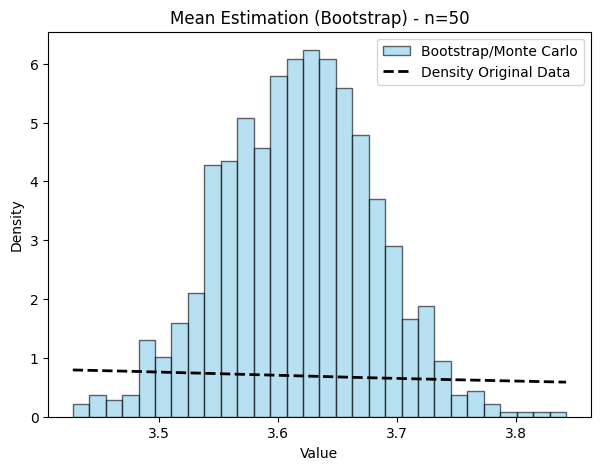

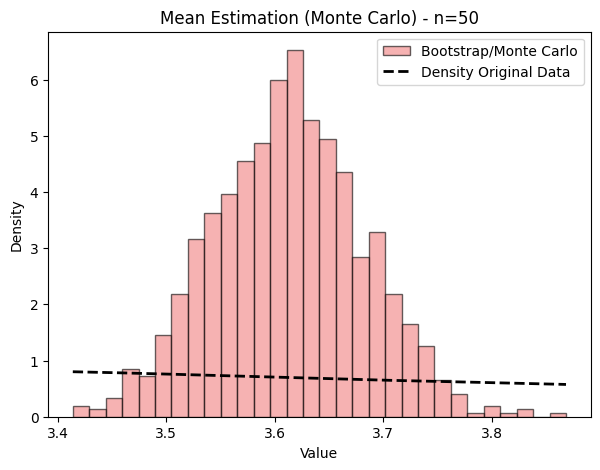

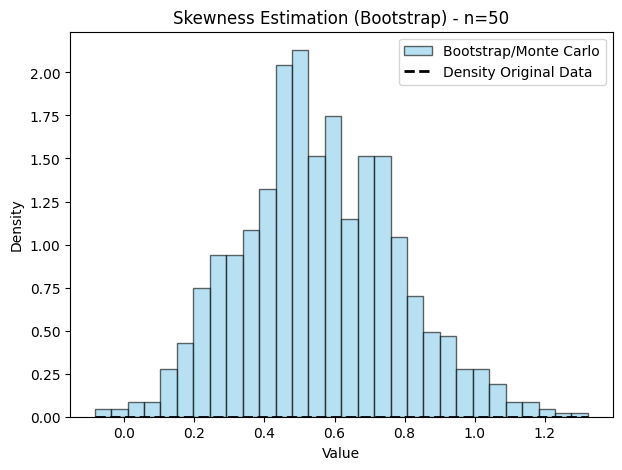

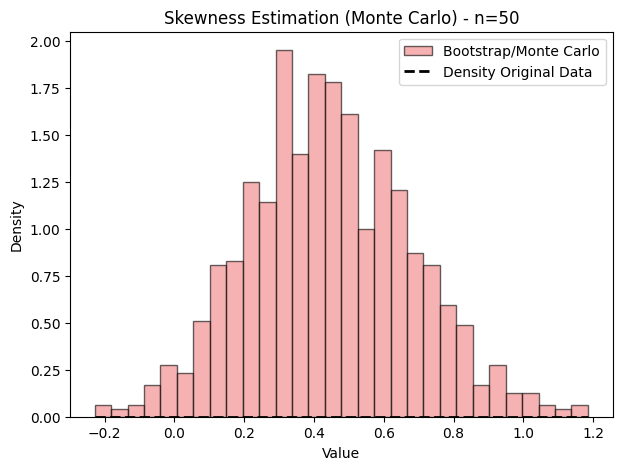

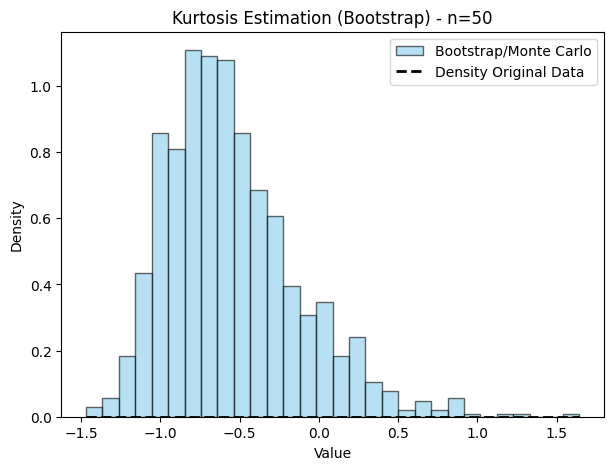

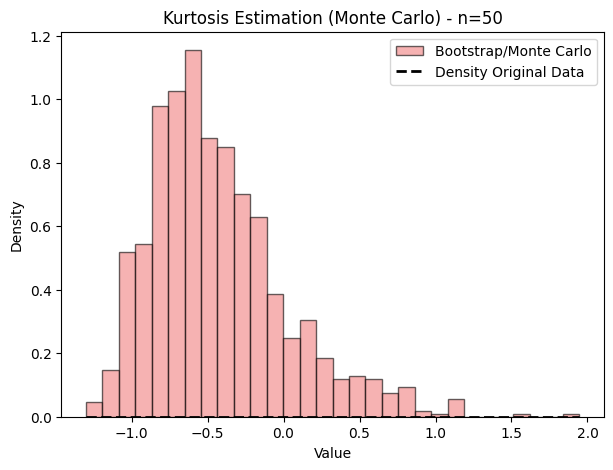


===== Resampling dengan ukuran 100 =====


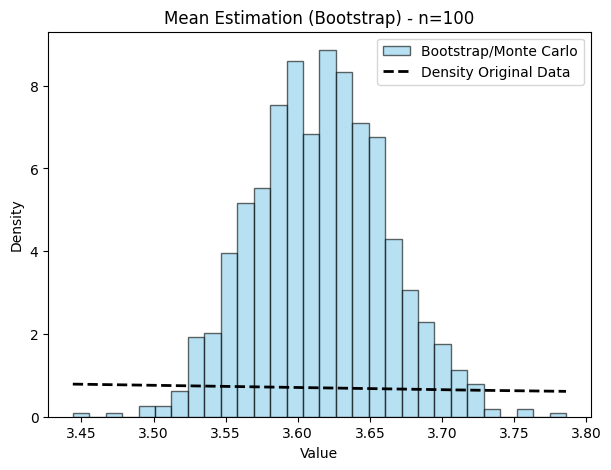

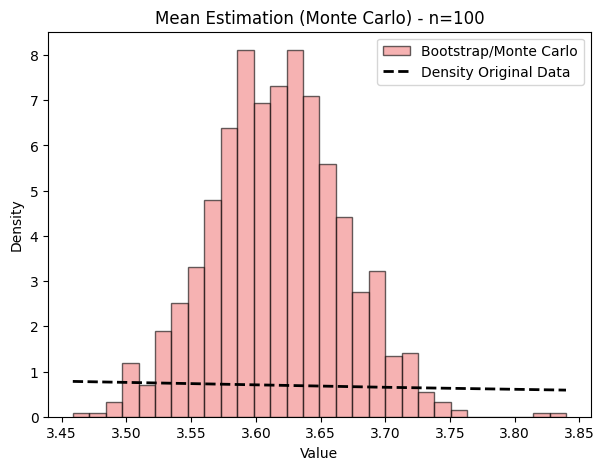

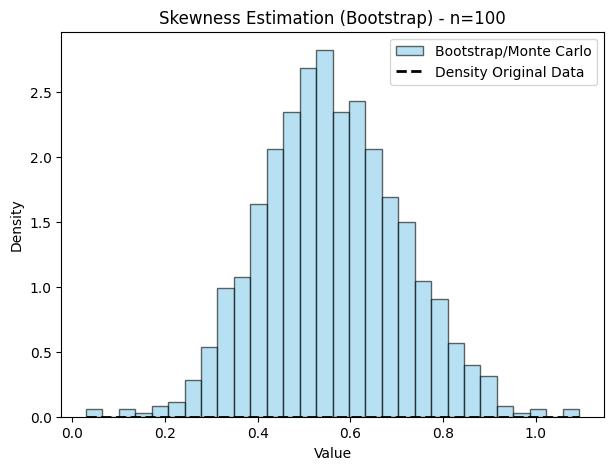

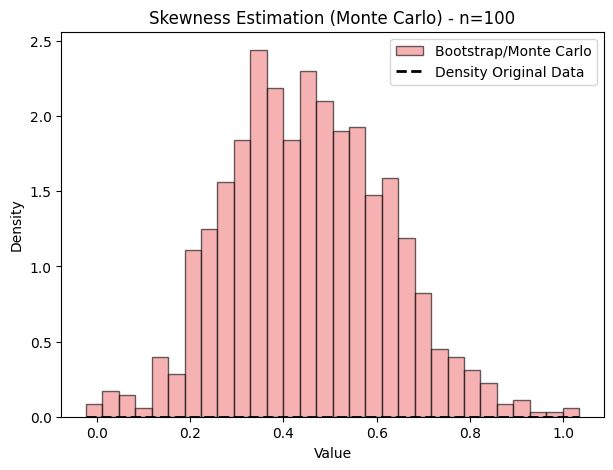

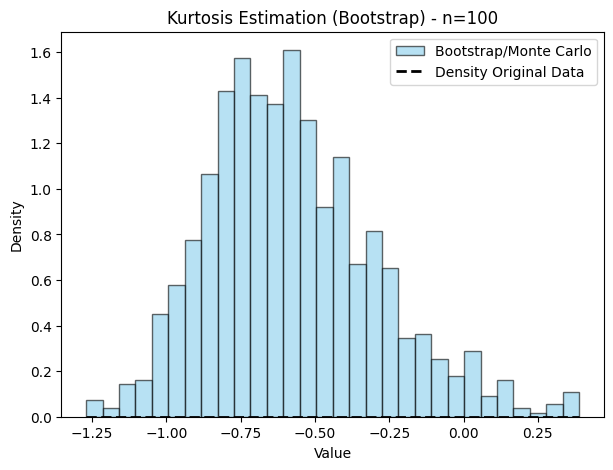

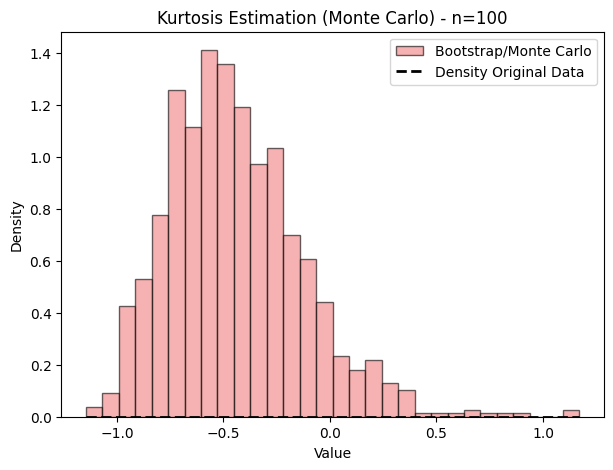


===== Resampling dengan ukuran 500 =====


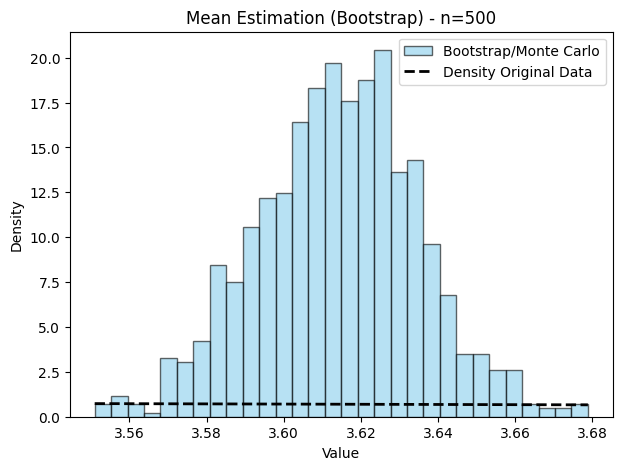

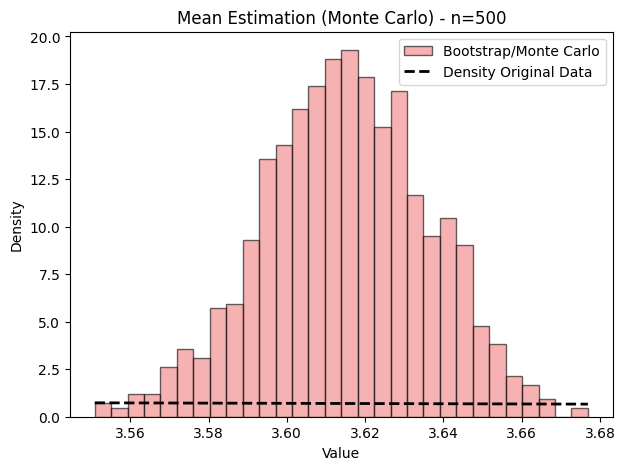

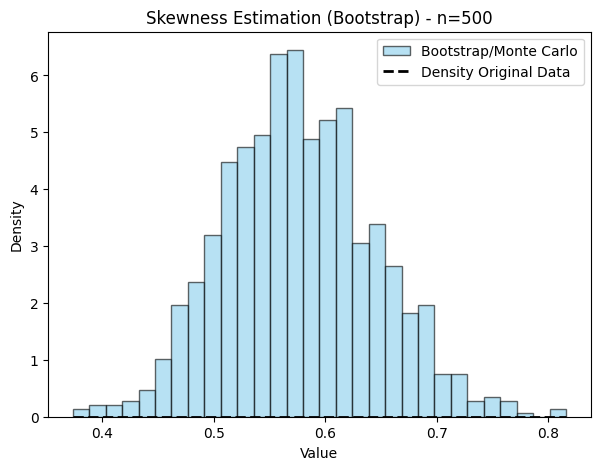

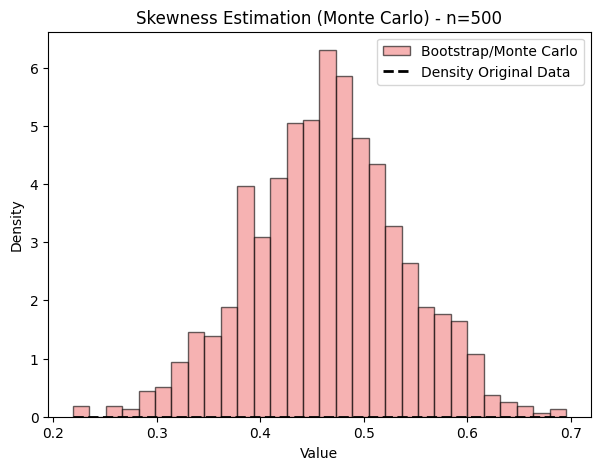

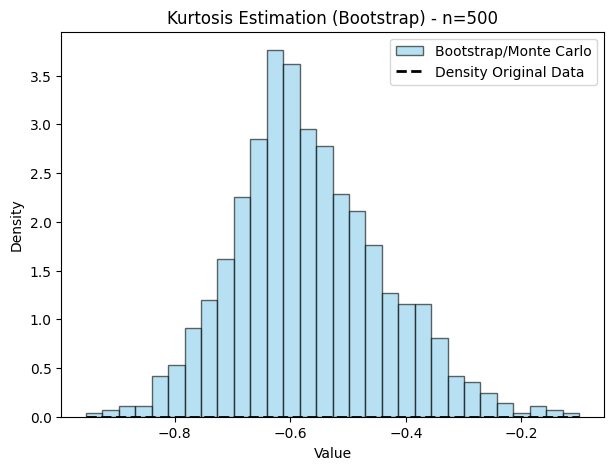

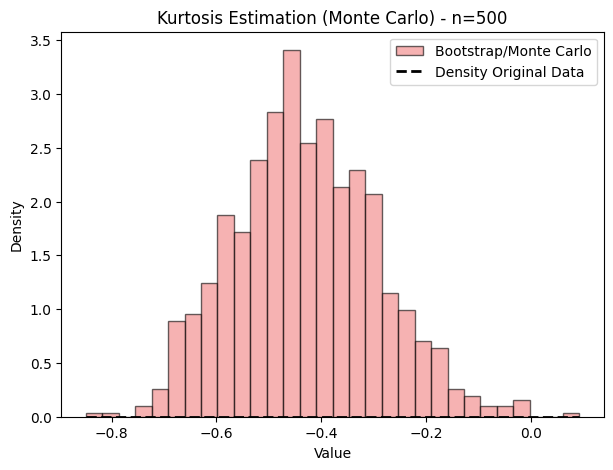


===== Resampling dengan ukuran 1000 =====


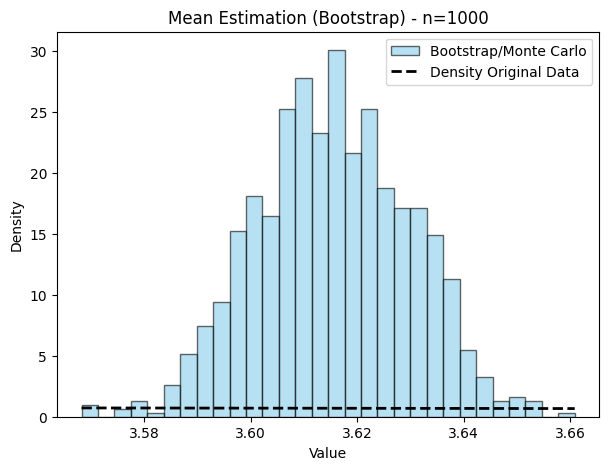

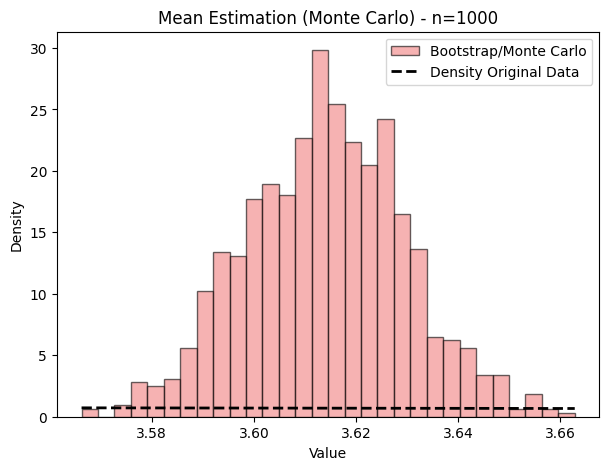

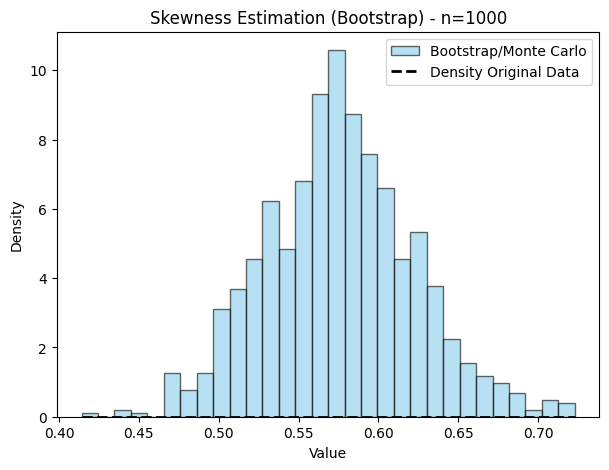

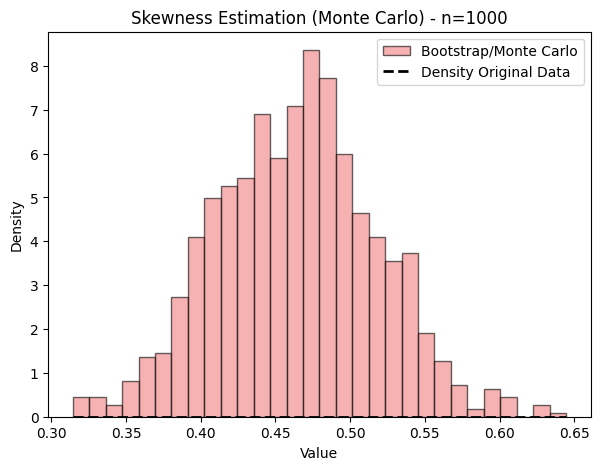

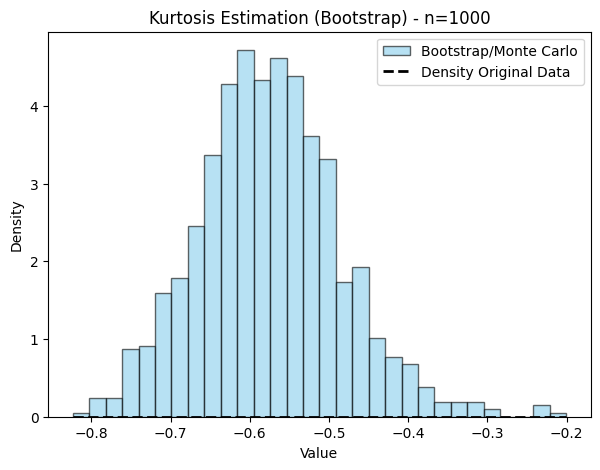

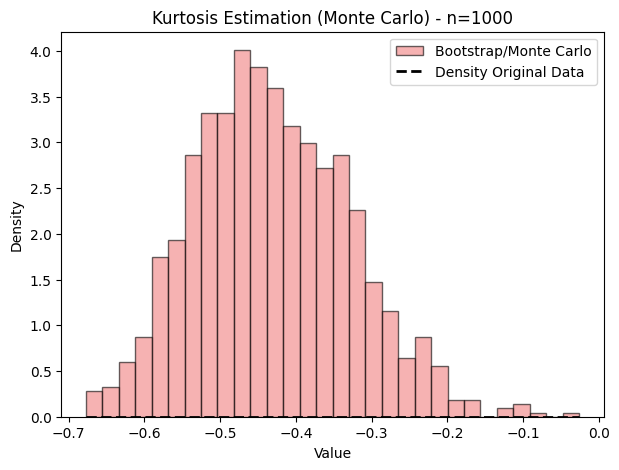

In [5]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# **1. Load Data Gempa Bumi**
data = pd.read_excel('/content/Data Gempa Bumi.xlsx')
data = data.values.flatten()

# **2. Parameter Resampling**
sample_sizes = [50, 100, 500, 1000]
B = 1000  # Jumlah bootstrap/Monte Carlo iteration

# **3. Fungsi untuk Membuat Histogram**
def plot_histogram(estimates, title, color):
    plt.figure(figsize=(7, 5))

    # Histogram hasil resampling
    plt.hist(estimates, bins=30, density=True, alpha=0.6, color=color, edgecolor="black", label="Bootstrap/Monte Carlo")

    # Kurva kepadatan dari data awal
    kde_data = gaussian_kde(data)
    x_vals = np.linspace(min(estimates), max(estimates), 1000)
    plt.plot(x_vals, kde_data(x_vals), color="black", linewidth=2, linestyle="dashed", label="Density Original Data")

    # Plot
    plt.title(title)
    plt.xlabel("Value")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

# **4. Simulasi Resampling**
for n in sample_sizes:
    print(f"\n===== Resampling dengan ukuran {n} =====")

    # Simpan estimasi
    bootstrap_means, bootstrap_skew, bootstrap_kurt = [], [], []
    mc_means, mc_skew, mc_kurt = [], [], []

    # **5. Bootstrap Resampling**
    for _ in range(B):
        resampled_data = np.random.choice(data, size=n, replace=True)
        bootstrap_means.append(np.mean(resampled_data))
        bootstrap_skew.append(stats.skew(resampled_data))
        bootstrap_kurt.append(stats.kurtosis(resampled_data, fisher=True))

    # **6. Monte Carlo Resampling (dengan KDE)**
    kde = gaussian_kde(data)
    for _ in range(B):
        mc_data = kde.resample(n)[0]
        mc_means.append(np.mean(mc_data))
        mc_skew.append(stats.skew(mc_data))
        mc_kurt.append(stats.kurtosis(mc_data, fisher=True))

    # **7. Plot Histogram & Kurva Kepadatan Data Asli**
    plot_histogram(bootstrap_means, f"Mean Estimation (Bootstrap) - n={n}", "skyblue")
    plot_histogram(mc_means, f"Mean Estimation (Monte Carlo) - n={n}", "lightcoral")

    plot_histogram(bootstrap_skew, f"Skewness Estimation (Bootstrap) - n={n}", "skyblue")
    plot_histogram(mc_skew, f"Skewness Estimation (Monte Carlo) - n={n}", "lightcoral")

    plot_histogram(bootstrap_kurt, f"Kurtosis Estimation (Bootstrap) - n={n}", "skyblue")
    plot_histogram(mc_kurt, f"Kurtosis Estimation (Monte Carlo) - n={n}", "lightcoral")



===== Histogram dengan ukuran sampel 50 =====


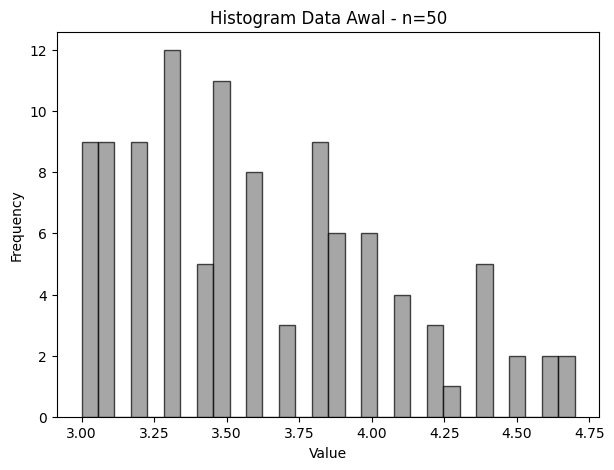

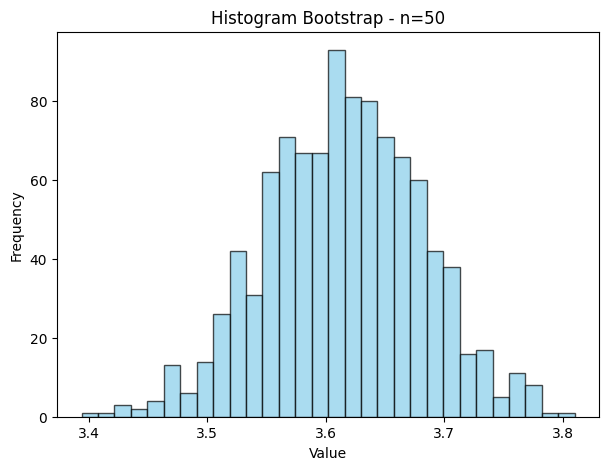

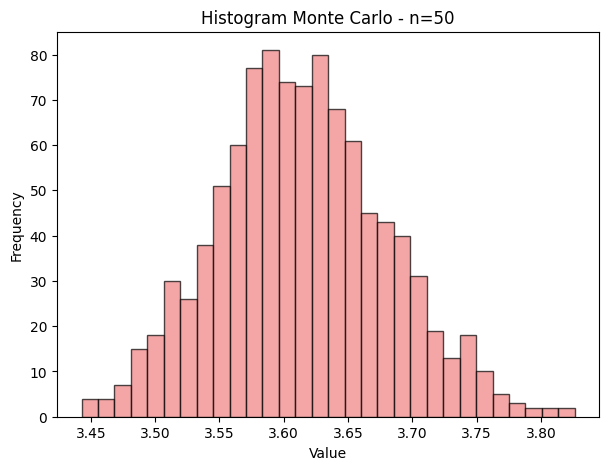


===== Histogram dengan ukuran sampel 100 =====


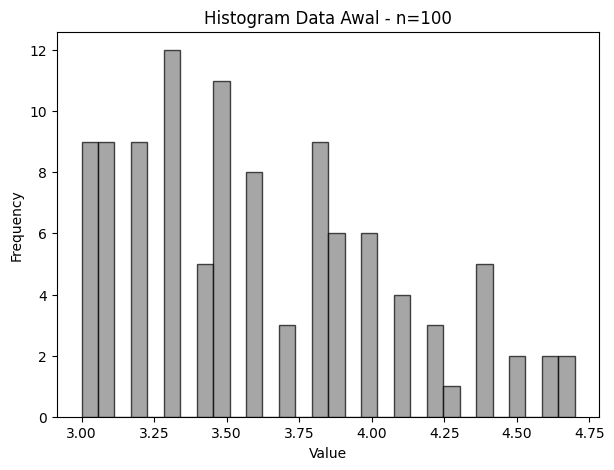

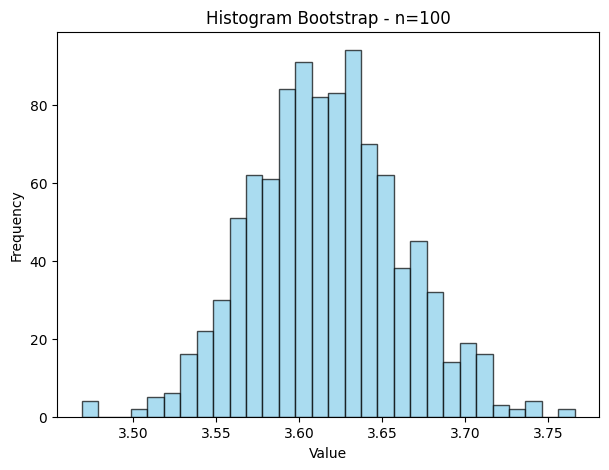

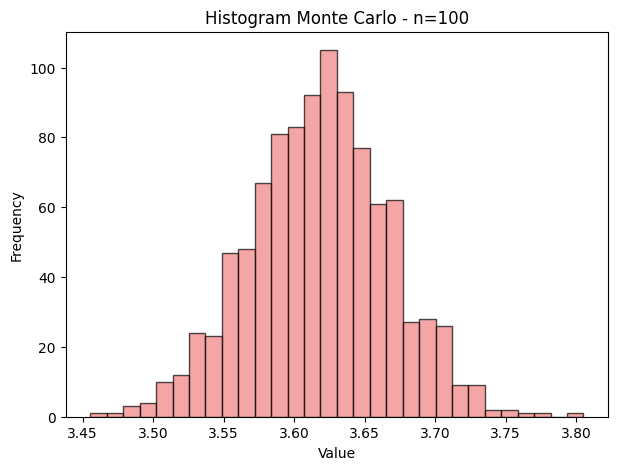


===== Histogram dengan ukuran sampel 500 =====


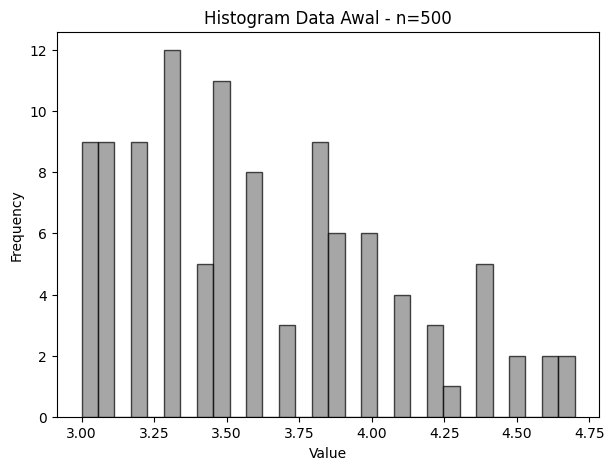

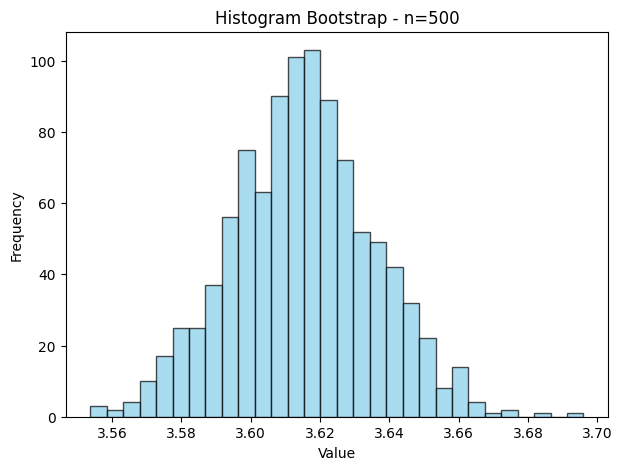

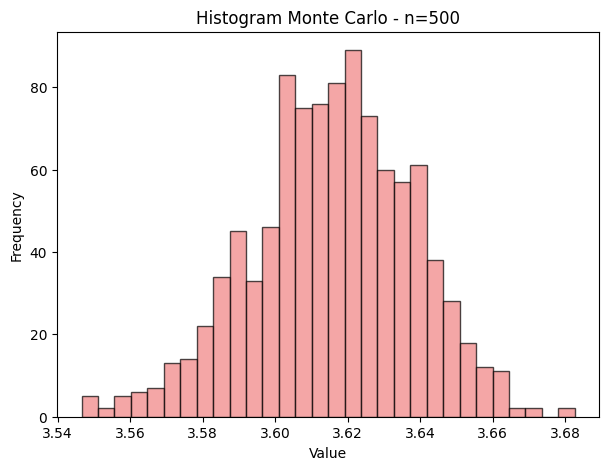


===== Histogram dengan ukuran sampel 1000 =====


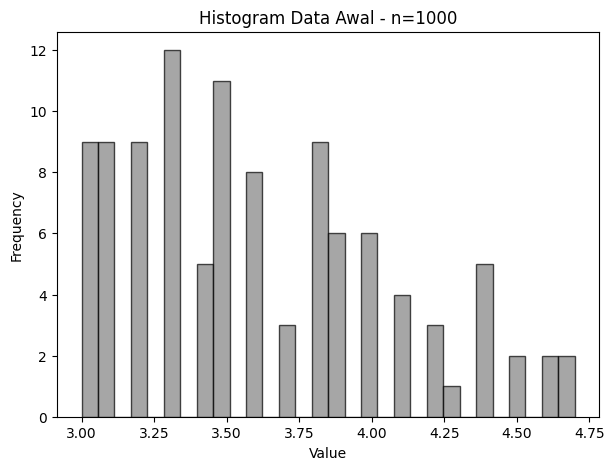

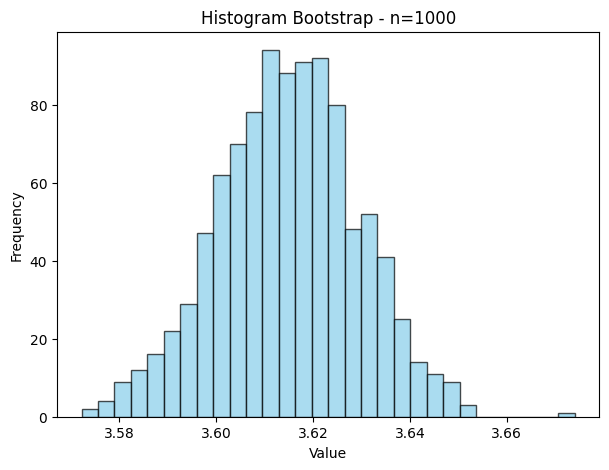

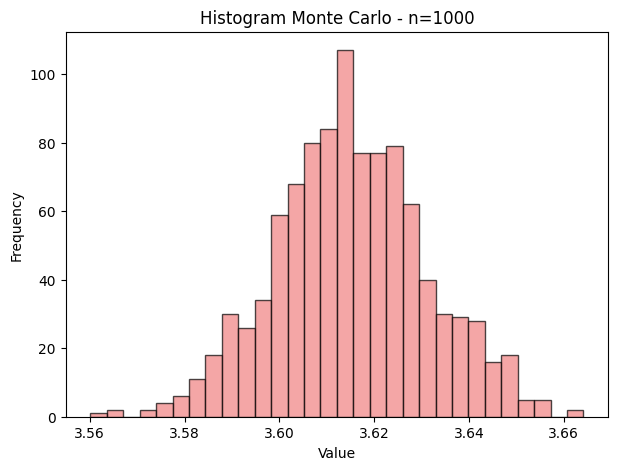

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde

# **1. Load Data Gempa Bumi**
data = pd.read_excel('/content/Data Gempa Bumi.xlsx')
data = data.values.flatten()

# **2. Parameter Resampling**
sample_sizes = [50, 100, 500, 1000]  # Ukuran sampel
B = 1000  # Jumlah bootstrap/Monte Carlo iteration

# **3. Fungsi untuk Membuat Histogram**
def plot_histogram(data_samples, title, color):
    plt.figure(figsize=(7, 5))
    plt.hist(data_samples, bins=30, color=color, alpha=0.7, edgecolor="black")
    plt.title(title)
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.show()

# **4. Simulasi Resampling**
for n in sample_sizes:
    print(f"\n===== Histogram dengan ukuran sampel {n} =====")

    # **Plot Histogram Data Awal**
    plot_histogram(data, f"Histogram Data Awal - n={n}", "gray")

    # Simpan estimasi
    bootstrap_samples = []
    monte_carlo_samples = []

    # **5. Bootstrap Resampling**
    for _ in range(B):
        resampled_data = np.random.choice(data, size=n, replace=True)
        bootstrap_samples.append(np.mean(resampled_data))

    # **6. Monte Carlo Resampling (dengan KDE)**
    kde = gaussian_kde(data)
    for _ in range(B):
        mc_data = kde.resample(n)[0]
        monte_carlo_samples.append(np.mean(mc_data))

    # **7. Plot Histogram Bootstrap & Monte Carlo**
    plot_histogram(bootstrap_samples, f"Histogram Bootstrap - n={n}", "skyblue")
    plot_histogram(monte_carlo_samples, f"Histogram Monte Carlo - n={n}", "lightcoral")
